##

In [9]:
# ---------------------------------------------------------
# 1. CORE DATA & MATH LIBRARIES
# ---------------------------------------------------------
import numpy as np      # Used for fast mathematical calculations and handling numerical arrays
import pandas as pd     # Used to load, clean, filter, and analyze tabular data (dataframes)

# ---------------------------------------------------------
# 2. VISUALIZATION & PLOTTING LIBRARIES
# ---------------------------------------------------------
import matplotlib.pyplot as plt  # Used to create charts, plots, and graphs
import seaborn as sns            # Built on top of matplotlib to make statistical charts look prettier


# ---------------------------------------------------------
# 3. MACHINE LEARNING & MODELING (Scikit-Learn)
# ---------------------------------------------------------
# Used to split data into 80% training data and 20% testing data
from sklearn.model_selection import train_test_split

# Used to convert text labels (like 'Yes'/'No' or 'Male'/'Female') into numbers (0 or 1)
from sklearn.preprocessing import LabelEncoder

# The main AI algorithms:
# - LogisticRegression: Standard banking model for calculating default probability (simple & explainable)
# - RandomForestClassifier: Advanced decision-tree model for comparison and higher accuracy
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation tools to measure performance (Accuracy, Precision, Recall, and AUC-ROC score)
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# ---------------------------------------------------------
# 4. ENVIRONMENT & PLOT STYLING
# ---------------------------------------------------------
import warnings
warnings.filterwarnings('ignore')  # Hides unnecessary warning messages to keep the output clean

# Make charts look clean and high resolution
plt.rcParams['figure.dpi'] = 120    # Increases picture quality/sharpness of plots
sns.set_theme(style='whitegrid')    # Sets a clean grid background for all charts

print("✅ All libraries loaded successfully!")

✅ All libraries loaded successfully!


---
## 🧹 Stage 1: Load Data & Data Cleaning

Real banking data is never clean. This dataset has realistic missing values
injected to mirror what you actually see in LOS (Loan Origination System) and
CBS (Core Banking System) exports:

| Column | Sheet | Why Nulls Appear in Real Banks |
|--------|-------|-------------------------------|
| `BORROWING_TYPE` | APPLICATION MASTER | Missing product tag — legacy LOS exports |
| `TENURE` | APPLICATION MASTER | Contract terms not entered — data entry gap |
| `REQUESTED_AMOUNT` | APPLICATION MASTER | Application abandoned mid-way |
| `APPLICATION_DATE` | APPLICATION MASTER | System migration data loss |
| `Gender` | CUSTOMER_MASTER | Optional field — customer didn't fill |
| `AGE` | CUSTOMER_MASTER | DOB present but age not computed |
| `Region` | CUSTOMER_MASTER | State-to-region mapping incomplete |
| `City` / `State` | CUSTOMER_MASTER | Address fields partially missing |

**Cleaning Strategy:**  
- Drop rows where critical fields are null (no amount = can't underwrite)  
- Impute with mode/median for non-critical fields  
- Derive `Region` from `State` for remaining nulls  
- Always document what you dropped and why (audit trail)


In [10]:

import pandas as pd

# ---------------------------------------------------------
# 1. LOAD DATA FROM EXCEL SHEETS
# ---------------------------------------------------------
# Read the loan application details from the "APPLICATION MASTER" sheet

app = pd.read_excel('ALL_DATA_FILES_WithNulls.xlsx',sheet_name='APPLICATION MASTER')

# Read customer demographics (Age, Gender, Location) from the "CUSTOMER_MASTER" sheet

cust = pd.read_excel('ALL_DATA_FILES_WithNulls.xlsx',sheet_name='CUSTOMER_MASTER')


# ---------------------------------------------------------
# 2. AUDIT DATA SIZE AND DATE RANGE
# ---------------------------------------------------------
# app.shape[0] gives the total rows, app.shape[1] gives the total columns
# Remove timezone text in brackets
app["APPLICATION_DATE"] = (
    app["APPLICATION_DATE"]
    .astype(str)
    .str.replace(r" \(.*\)$", "", regex=True)
)

# Convert to datetime
app["APPLICATION_DATE"] = pd.to_datetime(
    app["APPLICATION_DATE"],
    errors="coerce"
)

print(f'APPLICATION MASTER  : {app.shape[0]:,} rows × {app.shape[1]} cols')
print(f'CUSTOMER MASTER     : {cust.shape[0]:,} rows × {cust.shape[1]} cols')
# Check the start date and end date of applications in the dataset

print(
    f'Date range          : '
    f'{app["APPLICATION_DATE"].min()} → '
    f'{app["APPLICATION_DATE"].max()}'
)

APPLICATION MASTER  : 10,108 rows × 6 cols
CUSTOMER MASTER     : 6,001 rows × 27 cols
Date range          : 2016-01-01 05:30:00+05:30 → 2020-12-28 05:30:00+05:30


In [11]:
# Quick count for Application Master
print(app.isnull().sum())

# Quick count for Customer Master core columns
print(cust[['CUSTOMER_NUMBER', 'AGE', 'Gender', 'Region', 'State', 'City']].isnull().sum())

APPLICATION_NUMBER      0
CUSTOMER_NUMBER         0
APPLICATION_DATE      315
BORROWING_TYPE        769
REQUESTED_AMOUNT      616
TENURE                508
dtype: int64
CUSTOMER_NUMBER      0
AGE                443
Gender             592
Region             707
State              318
City               243
dtype: int64


In [12]:
# ============================================================
# STEP 1: REMOVE ROWS WITH IMPORTANT MISSING VALUES
# ============================================================

# REQUESTED_AMOUNT is important.
# If it is missing, we cannot process the loan application.

before = len(app)

app = app.dropna(subset=['REQUESTED_AMOUNT'])

after = len(app)

print("Rows removed because REQUESTED_AMOUNT is missing:", before - after)


# APPLICATION_DATE is also important.
# We need it for date/vintage analysis.

before = len(app)

app = app.dropna(subset=['APPLICATION_DATE'])

after = len(app)

print("Rows removed because APPLICATION_DATE is missing:", before - after)


# ============================================================
# STEP 2: FILL MISSING VALUES IN BORROWING_TYPE
# ============================================================

# First, find the most common BORROWING_TYPE.
# mode() gives us the most frequently occurring value.

mode_product = app['BORROWING_TYPE'].mode()[0]

print("Most common borrowing type:", mode_product)


# Count how many values are missing before filling them.

null_count = app['BORROWING_TYPE'].isnull().sum()


# Fill missing BORROWING_TYPE values with the most common value.

app['BORROWING_TYPE'] = app['BORROWING_TYPE'].fillna(mode_product)

print("BORROWING_TYPE missing values filled:", null_count)


# ============================================================
# STEP 3: FILL MISSING TENURE VALUES
# ============================================================

# Some TENURE values may be missing.
# Instead of using one median for all products,
# we calculate the median separately for each BORROWING_TYPE.because morguage tenure  hase 10 to 15 yr and credit card tenure has 3 yr

# Fill missing TENURE using the MEDIAN TENURE of the SAME product group
# Reason: Mortgage tenure (15-30 yrs) is very different from Credit Card (3 yrs)
# So filling with one single global median would be wrong — we fill "per group" instead
# transform() performs an operation on each group and returns a result with the same number of rows as the original DataFrame.
# x represents the TENURE values of one group.
# x.median() calculates the median tenure for that group.
# x.fillna(...) replaces only the missing values in that group.



null_count = app['TENURE'].isnull().sum()

app['TENURE'] = app.groupby('BORROWING_TYPE')['TENURE'].transform(
    lambda x: x.fillna(x.median())
)

print("TENURE missing values filled:", null_count)


# ============================================================
# STEP 4: CHECK THE FINAL DATA
# ============================================================

print("\n✅Application Master after cleaning:")
print("Number of rows:", len(app))


# Check how many missing values are still present.

remaining_nulls = app.isnull().sum().sum()

print("\nTotal remaining missing values:", remaining_nulls)

Rows removed because REQUESTED_AMOUNT is missing: 616
Rows removed because APPLICATION_DATE is missing: 298
Most common borrowing type: CREDIT CARD
BORROWING_TYPE missing values filled: 704
TENURE missing values filled: 456

✅Application Master after cleaning:
Number of rows: 9194

Total remaining missing values: 0


##          OR

In [13]:
# ═══════════════════════════════════════════════════════════
# STEP 1: DROP ROWS WHERE CRITICAL DATA IS MISSING
# (If these are missing, we literally cannot use the row)
# ═══════════════════════════════════════════════════════════

# Save row count BEFORE dropping, just to measure how many we lose
before = len(app)

# Drop rows where REQUESTED_AMOUNT is missing
# Reason: without loan amount, we can't calculate EMI/TDI/LTV — row is useless
app.dropna(subset=['REQUESTED_AMOUNT'], inplace=True)
print(f'Dropped {before - len(app):,} rows missing REQUESTED_AMOUNT (application abandoned)')

# Save row count again before the next drop
before = len(app)

# Drop rows where APPLICATION_DATE is missing
# Reason: without a date, we can't do any time-based (yearly/monthly) analysis
app.dropna(subset=['APPLICATION_DATE'], inplace=True)
print(f'Dropped {before - len(app):,} rows missing APPLICATION_DATE (system migration loss)')


# ═══════════════════════════════════════════════════════════
# STEP 2: FILL MISSING VALUES FOR NON-CRITICAL COLUMNS
# (These are useful but not "deal-breakers", so we fill instead of drop)
# ═══════════════════════════════════════════════════════════

# Find the most common value (mode) in BORROWING_TYPE, e.g. "PERSONAL LOAN"
mode_product = app['BORROWING_TYPE'].mode()[0]

# Count how many rows are missing BORROWING_TYPE (just for the print message)
null_count = app['BORROWING_TYPE'].isnull().sum()

# Fill missing BORROWING_TYPE with the most common product (mode)
# Reason: it's a category column, so "most common" is the safest guess
app['BORROWING_TYPE'].fillna(mode_product, inplace=True)
print(f'Imputed {null_count:,} BORROWING_TYPE nulls → mode: "{mode_product}"')

# Count how many rows are missing TENURE (just for the print message)
null_count = app['TENURE'].isnull().sum()

# Fill missing TENURE using the MEDIAN TENURE of the SAME product group
# Reason: Mortgage tenure (15-30 yrs) is very different from Credit Card (3 yrs)
# So filling with one single global median would be wrong — we fill "per group" instead
app['TENURE'] = app.groupby('BORROWING_TYPE')['TENURE'].transform(
    lambda x: x.fillna(x.median())
)
print(f'Imputed {null_count:,} TENURE nulls → median per product')


# ═══════════════════════════════════════════════════════════
# STEP 3: FINAL CHECK — confirm cleaning worked
# ═══════════════════════════════════════════════════════════
print(f'\n✅ APPLICATION MASTER after cleaning: {len(app):,} rows')
print(f'   Remaining nulls: {app.isnull().sum().sum()}')


Dropped 0 rows missing REQUESTED_AMOUNT (application abandoned)
Dropped 0 rows missing APPLICATION_DATE (system migration loss)
Imputed 0 BORROWING_TYPE nulls → mode: "CREDIT CARD"
Imputed 0 TENURE nulls → median per product

✅ APPLICATION MASTER after cleaning: 9,194 rows
   Remaining nulls: 0


In [14]:
app.isnull().sum()

APPLICATION_NUMBER    0
CUSTOMER_NUMBER       0
APPLICATION_DATE      0
BORROWING_TYPE        0
REQUESTED_AMOUNT      0
TENURE                0
dtype: int64

In [15]:
# ============================================================
# STEP 3: CLEAN CUSTOMER MASTER
# ============================================================

# ------------------------------------------------------------
# STEP 1: SELECT ONLY THE COLUMNS WE NEED
# ------------------------------------------------------------

# We only need these columns for our analysis.
# WHAT HAPPENED  : We picked only 6 specific columns (ID, Age, Gender, Region, State, City) from the raw customer table.
# WHY WE USE THIS: Raw databases contain hundreds of unused tracking columns. Filtering simplifies our code and speeds up processing.

cust_clean = cust[
    ['CUSTOMER_NUMBER', 'AGE', 'Gender', 'Region', 'State', 'City']
].copy()

print("Customer data selected successfully")


# ------------------------------------------------------------
# STEP 2: HANDLE MISSING AGE VALUES
# ------------------------------------------------------------

# First, find the median age.
# WHAT HAPPENED  : We calculated the middle age (median = 34) of all customers, filled missing age blanks with 34, and converted decimals to whole numbers.
# WHY WE USE THIS: We use median instead of average (mean) because average is easily distorted by extreme values (like 100-year-olds). Whole numbers are required because age isn't measured in decimals in credit scores.

median_age = cust_clean['AGE'].median()

print("Median age:", median_age)


# Count how many AGE values are missing.

null_count = cust_clean['AGE'].isnull().sum()

print("Missing AGE values:", null_count)


# Fill missing AGE values with the median age.

cust_clean['AGE'] = cust_clean['AGE'].fillna(median_age)


# Convert AGE into integer format.

cust_clean['AGE'] = cust_clean['AGE'].astype(int)

print("Missing AGE values filled with median age")


# ------------------------------------------------------------
# STEP 3: HANDLE MISSING GENDER VALUES
# ------------------------------------------------------------

# Find the most common Gender.
# WHAT HAPPENED  : We found the most frequent gender category ('Male' or 'Female') in our database and used it to fill blank gender cells.
# WHY WE USE THIS: Gender is text/category data, so we cannot calculate a median or average. Using .mode()[0] fills missing values with the statistically most likely option.


gender_mode = cust_clean['Gender'].mode()[0]

print("Most common Gender:", gender_mode)


# Count missing Gender values.

null_count = cust_clean['Gender'].isnull().sum()


# Fill missing Gender values with the most common Gender.

cust_clean['Gender'] = cust_clean['Gender'].fillna(gender_mode)

print("Missing Gender values filled:", null_count)


# ------------------------------------------------------------------------------
# 4. RECOVER MISSING REGIONS FROM STATE NAMES (FEATURE ENGINEERING)
#             (Create state to region mapping dictionary)
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : We created a dictionary mapping US States to Regions (e.g., 'CA' -> 'West'). If Region was missing, Python looked at the customer's State to automatically fill in the correct Region.
# WHY WE USE THIS: This is called Data Recovery. Instead of guessing or dropping missing data, we use existing secondary information (State) to logically deduce the missing primary information (Region).
# Some customers may have State information
# but their Region is missing.
#
# We can use State to find the Region.

state_to_region = {

    # Western states
    'CA': 'West',
    'OR': 'West',
    'WA': 'West',
    'NV': 'West',
    'AZ': 'West',
    'CO': 'West',
    'UT': 'West',
    'NM': 'West',
    'ID': 'West',
    'MT': 'West',
    'WY': 'West',
    'AK': 'West',
    'HI': 'West',

    # Southern states
    'TX': 'South',
    'FL': 'South',
    'GA': 'South',
    'NC': 'South',
    'VA': 'South',
    'SC': 'South',
    'AL': 'South',
    'MS': 'South',
    'LA': 'South',
    'AR': 'South',
    'TN': 'South',
    'KY': 'South',
    'WV': 'South',
    'OK': 'South',
    'MD': 'South',
    'DE': 'South',
    'DC': 'South',

    # Northeastern states
    'NY': 'Northeast',
    'PA': 'Northeast',
    'MA': 'Northeast',
    'NJ': 'Northeast',
    'CT': 'Northeast',
    'NH': 'Northeast',
    'VT': 'Northeast',
    'ME': 'Northeast',
    'RI': 'Northeast',

    # Midwestern states
    'IL': 'Midwest',
    'OH': 'Midwest',
    'MI': 'Midwest',
    'IN': 'Midwest',
    'WI': 'Midwest',
    'MN': 'Midwest',
    'IA': 'Midwest',
    'MO': 'Midwest',
    'KS': 'Midwest',
    'NE': 'Midwest',
    'SD': 'Midwest',
    'ND': 'Midwest'
}


# ------------------------------------------------------------
# STEP 5: FILL MISSING REGION USING STATE
# ------------------------------------------------------------

# Count missing Region values before filling.

null_region_before = cust_clean['Region'].isnull().sum()

print("Missing Region values before:", null_region_before)


# Select only rows where Region is missing.
# Then use State to find the correct Region.

cust_clean.loc[cust_clean['Region'].isnull(),'Region'] = cust_clean.loc[cust_clean['Region'].isnull(),'State'].map(state_to_region)


# Count missing Region values after mapping.

null_region_after = cust_clean['Region'].isnull().sum()

print("Missing Region values after:", null_region_after)


# Calculate how many Region values were successfully filled.

filled_region = null_region_before - null_region_after

print("Region values filled using State:", filled_region)


# ------------------------------------------------------------
# STEP 6: HANDLE REMAINING REGION NULL VALUES
# ------------------------------------------------------------

# If Region is still missing,
# replace it with "Unknown".

cust_clean['Region'] = cust_clean['Region'].fillna('Unknown')

print("Remaining Region nulls filled with 'Unknown'")


# ------------------------------------------------------------
# STEP 7: HANDLE MISSING CITY AND STATE
# ------------------------------------------------------------

# City and State are not critical for our model.
# Therefore, if they are missing,
# we will replace them with "Unknown".

for column in ['City', 'State']:

    # Count missing values
    null_count = cust_clean[column].isnull().sum()

    # Replace missing values
    cust_clean[column] = cust_clean[column].fillna('Unknown')

    # Display result only if missing values existed
    if null_count > 0:
        print(column, "missing values filled:", null_count)


# ------------------------------------------------------------
# STEP 8: FINAL CHECK
# ------------------------------------------------------------

print("\n✅Customer Master after cleaning")

print("Number of rows:", len(cust_clean))


# Count all remaining missing values.

remaining_nulls = cust_clean.isnull().sum().sum()

print("Total remaining missing values:", remaining_nulls)

Customer data selected successfully
Median age: 44.0
Missing AGE values: 443
Missing AGE values filled with median age
Most common Gender: M
Missing Gender values filled: 592
Missing Region values before: 707
Missing Region values after: 38
Region values filled using State: 669
Remaining Region nulls filled with 'Unknown'
City missing values filled: 243
State missing values filled: 318

✅Customer Master after cleaning
Number of rows: 6001
Total remaining missing values: 0


##  OR

In [16]:
# ==============================================================================
# STEP 3: CLEAN CUSTOMER DEMOGRAPHIC DATA (CUSTOMER MASTER)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. SELECT RELEVANT COLUMNS
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : We picked only 6 specific columns (ID, Age, Gender, Region, State, City) from the raw customer table.
# WHY WE USE THIS: Raw databases contain hundreds of unused tracking columns. Filtering simplifies our code and speeds up processing.
columns_needed = ['CUSTOMER_NUMBER', 'AGE', 'Gender', 'Region', 'State', 'City']
cust_clean = cust[columns_needed].copy()


# ------------------------------------------------------------------------------
# 2. FIX MISSING AGE VALUES
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : We calculated the middle age (median = 34) of all customers, filled missing age blanks with 34, and converted decimals to whole numbers.
# WHY WE USE THIS: We use median instead of average (mean) because average is easily distorted by extreme values (like 100-year-olds). Whole numbers are required because age isn't measured in decimals in credit scores.
median_age = cust_clean['AGE'].median()
missing_ages = cust_clean['AGE'].isnull().sum()

cust_clean['AGE'] = cust_clean['AGE'].fillna(median_age)
cust_clean['AGE'] = cust_clean['AGE'].astype(int)  # Converts 34.0 -> 34

print(f"Filled {missing_ages:,} blank Age records with median age: {int(median_age)} years old")


# ------------------------------------------------------------------------------
# 3. FIX MISSING GENDER VALUES
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : We found the most frequent gender category ('Male' or 'Female') in our database and used it to fill blank gender cells.
# WHY WE USE THIS: Gender is text/category data, so we cannot calculate a median or average. Using .mode()[0] fills missing values with the statistically most likely option.
most_common_gender = cust_clean['Gender'].mode()[0]
missing_genders = cust_clean['Gender'].isnull().sum()

cust_clean['Gender'] = cust_clean['Gender'].fillna(most_common_gender)

print(f"Filled {missing_genders:,} blank Gender records with most common gender: '{most_common_gender}'")


# ------------------------------------------------------------------------------
# 4. RECOVER MISSING REGIONS FROM STATE NAMES (FEATURE ENGINEERING)
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : We created a dictionary mapping US States to Regions (e.g., 'CA' -> 'West'). If Region was missing, Python looked at the customer's State to automatically fill in the correct Region.
# WHY WE USE THIS: This is called Data Recovery. Instead of guessing or dropping missing data, we use existing secondary information (State) to logically deduce the missing primary information (Region).
state_to_region = {
    'CA':'West', 'OR':'West', 'WA':'West', 'NV':'West', 'AZ':'West', 'CO':'West',
    'TX':'South', 'FL':'South', 'GA':'South', 'NC':'South', 'VA':'South', 'TN':'South',
    'NY':'Northeast', 'PA':'Northeast', 'MA':'Northeast', 'NJ':'Northeast',
    'IL':'Midwest', 'OH':'Midwest', 'MI':'Midwest', 'IN':'Midwest', 'WI':'Midwest'
}

missing_region_before = cust_clean['Region'].isnull().sum()

# Fill missing Region using State lookup
cust_clean['Region'] = cust_clean['Region'].fillna(cust_clean['State'].map(state_to_region))

missing_region_after = cust_clean['Region'].isnull().sum()
recovered_count = missing_region_before - missing_region_after

print(f"Recovered {recovered_count:,} missing Region entries by mapping from State codes")

# ------------------------------------------------------------------------------
# 5. FILL ANY LEFTOVER BLANK LOCATION FIELDS
# ------------------------------------------------------------------------------
# WHAT HAPPENED  : If Region, State, or City were still blank after mapping, we replaced the blanks with the string label 'Unknown'.
# WHY WE USE THIS: Machine learning algorithms fail if they encounter empty/NaN text cells. Giving them an explicit category named 'Unknown' lets the model learn patterns even for incomplete records.
cust_clean['Region'] = cust_clean['Region'].fillna('Unknown')
cust_clean['State']  = cust_clean['State'].fillna('Unknown')
cust_clean['City']   = cust_clean['City'].fillna('Unknown')


# ------------------------------------------------------------------------------
# SUMMARY REPORT
# ------------------------------------------------------------------------------
print("\n✅ CUSTOMER MASTER Cleaning Complete!")
print(f"   Final Customer Records : {len(cust_clean):,}")
print(f"   Remaining Null Values  : {cust_clean.isnull().sum().sum()}")


Filled 443 blank Age records with median age: 44 years old
Filled 592 blank Gender records with most common gender: 'M'
Recovered 414 missing Region entries by mapping from State codes

✅ CUSTOMER MASTER Cleaning Complete!
   Final Customer Records : 6,001
   Remaining Null Values  : 0


In [17]:
# ============================================================
# STEP 4: MERGE APPLICATION DATA WITH CUSTOMER DATA
# ============================================================

# We are combining:
# app         → Application Master
# cust_clean  → Clean Customer Master
#
# CUSTOMER_NUMBER is the common column in both tables.

df_clean = app.merge(
    cust_clean,
    on='CUSTOMER_NUMBER',
    how='left'
)

print("✅Data merged successfully")


# ============================================================
# STEP 1: CHECK THE SIZE OF FINAL DATASET
# ============================================================

# shape gives:
# number of rows and number of columns

print("Final dataset shape:", df_clean.shape)


# Example:
# (9500, 11)
#
# 9500 → rows
# 11   → columns


# ============================================================
# STEP 2: CHECK REMAINING NULL VALUES
# ============================================================

# isnull() checks missing values
# sum() counts them

total_nulls = df_clean.isnull().sum().sum()

print("Total missing values after merge:", total_nulls)


# ============================================================
# STEP 3: CLEANING SUMMARY
# ============================================================

print("\n📊CLEANING SUMMARY")


# Original number of application records

original_records = 10108

print("Original applications:", original_records)


# Number of records remaining after cleaning

cleaned_records = len(app)

print("Applications after cleaning:", cleaned_records)


# Calculate how many records were removed

records_lost = original_records - cleaned_records

print("Records lost:", records_lost)


# Calculate percentage of records removed

percentage_lost = (records_lost / original_records) * 100

print("Percentage of records lost:", round(percentage_lost, 1), "%")


# ============================================================
# STEP 4: FINAL DATASET INFORMATION
# ============================================================

print("Final clean dataset rows:", len(df_clean))

print("Final clean dataset columns:", df_clean.shape[1])


# ============================================================
# STEP 5: CHECK BORROWING TYPE
# ============================================================

print("\n✅Product mix after cleaning:")


# value_counts() tells us how many applications
# belong to each borrowing type.

product_count = df_clean['BORROWING_TYPE'].value_counts()

print(product_count)

✅Data merged successfully
Final dataset shape: (9194, 11)
Total missing values after merge: 0

📊CLEANING SUMMARY
Original applications: 10108
Applications after cleaning: 9194
Records lost: 914
Percentage of records lost: 9.0 %
Final clean dataset rows: 9194
Final clean dataset columns: 11

✅Product mix after cleaning:
BORROWING_TYPE
CREDIT CARD       3569
MORTGAGE          1991
PERSONAL LOAN     1655
AUTO LOAN         1153
LINE OF CREDIT     826
Name: count, dtype: int64


## OR

In [18]:
# ============================================================
# STEP 4: MERGE APPLICATION DATA AND CUSTOMER DATA
# ============================================================

# Merge app and cust_clean using CUSTOMER_NUMBER
# CUSTOMER_NUMBER is common in both datasets.

df_clean = pd.merge(
    app,
    cust_clean,
    on='CUSTOMER_NUMBER',
    how='left'
)

print("\n✅Data merged successfully")


# ============================================================
# CHECK FINAL DATASET
# ============================================================

# Check number of rows and columns

print("Final dataset shape:", df_clean.shape)


# Check total missing values

total_nulls = df_clean.isnull().sum().sum()

print("Total missing values:", total_nulls)


# ============================================================
# CLEANING SUMMARY
# ============================================================

original_records = 10108

print("\n📊CLEANING SUMMARY")

print("Original applications:", original_records)

print("Applications after cleaning:", len(app))


# Calculate records removed

records_lost = original_records - len(app)

print("Records lost:", records_lost)


# Calculate percentage of records lost

percentage_lost = (records_lost / original_records) * 100

print("Percentage of records lost:", round(percentage_lost, 1), "%")


# ============================================================
# FINAL DATASET INFORMATION
# ============================================================

print("Final clean dataset:", len(df_clean), "rows")

print("Final clean dataset:", df_clean.shape[1], "columns")


# ============================================================
# PRODUCT MIX
# ============================================================

print("\n✅Product mix after cleaning:")

# Count applications for each borrowing type

product_count = df_clean['BORROWING_TYPE'].value_counts()

print(product_count)

# "Take my df DataFrame and save it as df_clean.csv without saving the DataFrame index."
df.to_csv('df_clean.csv', index=False)



✅Data merged successfully
Final dataset shape: (9194, 11)
Total missing values: 0

📊CLEANING SUMMARY
Original applications: 10108
Applications after cleaning: 9194
Records lost: 914
Percentage of records lost: 9.0 %
Final clean dataset: 9194 rows
Final clean dataset: 11 columns

✅Product mix after cleaning:
BORROWING_TYPE
CREDIT CARD       3569
MORTGAGE          1991
PERSONAL LOAN     1655
AUTO LOAN         1153
LINE OF CREDIT     826
Name: count, dtype: int64


NameError: name 'df' is not defined

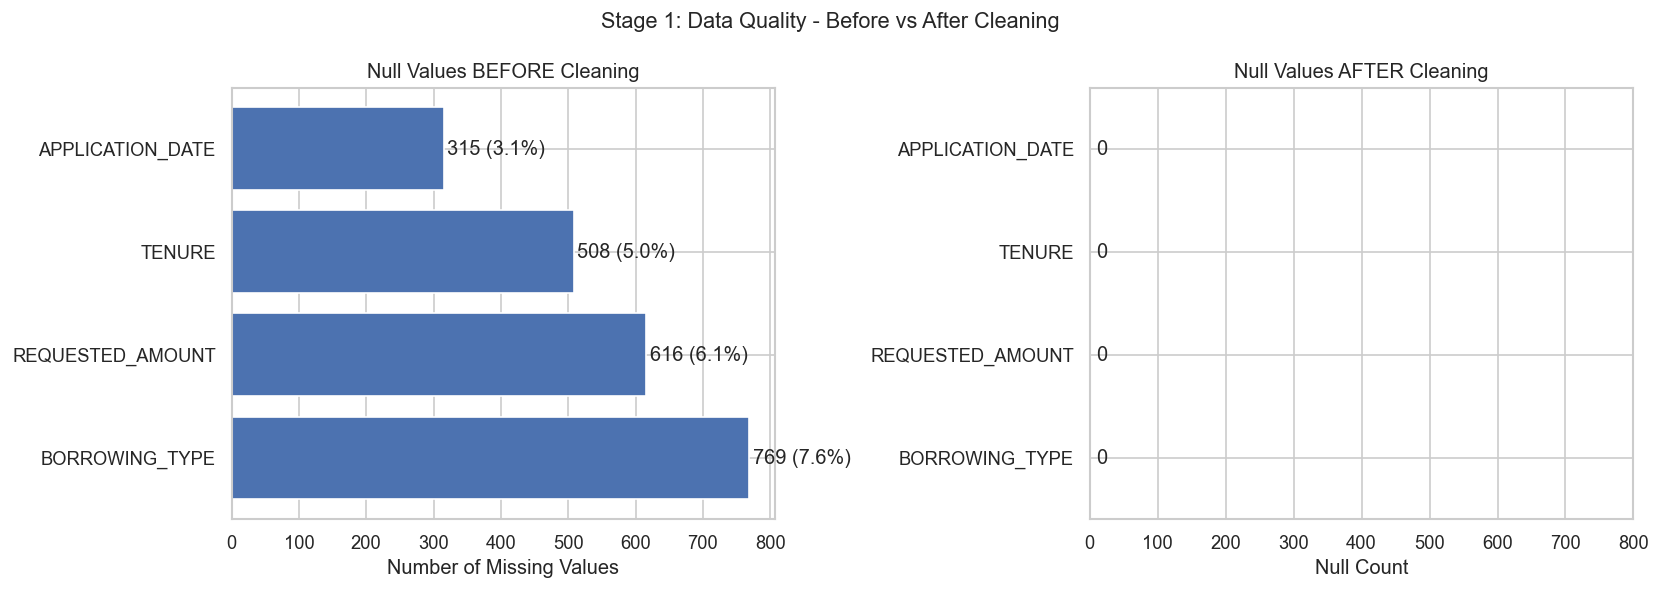

Stage 1 Data Cleaning completed successfully


In [ ]:
# ============================================================
# NULL VALUES: BEFORE VS AFTER CLEANING
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# STEP 1: CREATE THE DATA
# ------------------------------------------------------------

# Number of missing values BEFORE cleaning

before_data = {
    'BORROWING_TYPE': 769,
    'REQUESTED_AMOUNT': 616,
    'TENURE': 508,
    'APPLICATION_DATE': 315
}


# ------------------------------------------------------------
# STEP 2: CREATE TWO CHARTS
# ------------------------------------------------------------

# Create 1 row and 2 columns of charts

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Give the complete figure a title

fig.suptitle(
    'Stage 1: Data Quality - Before vs After Cleaning',
    fontsize=13
)


# ------------------------------------------------------------
# STEP 3: BEFORE CLEANING CHART
# ------------------------------------------------------------

# Create horizontal bar chart

axes[0].barh(
    list(before_data.keys()),
    list(before_data.values())
)


# Give the chart a title

axes[0].set_title(
    'Null Values BEFORE Cleaning'
)


# Give X-axis a name

axes[0].set_xlabel('Number of Missing Values')


# ------------------------------------------------------------
# STEP 4: DISPLAY VALUES ON BEFORE CHART
# ------------------------------------------------------------

# Add the number of missing values to each bar

for i, value in enumerate(before_data.values()):

    # Calculate percentage

    percentage = (value / 10108) * 100

    # Display count and percentage

    axes[0].text(
        value + 5,
        i,
        str(value) + ' (' + str(round(percentage, 1)) + '%)',
        va='center'
    )


# ------------------------------------------------------------
# STEP 5: AFTER CLEANING CHART
# ------------------------------------------------------------

# Create a list of column names

columns = list(before_data.keys())


# After cleaning, all these columns have 0 missing values

after_values = [0, 0, 0, 0]


# Create horizontal bar chart

axes[1].barh(
    columns,
    after_values
)


# Give the chart a title

axes[1].set_title(
    'Null Values AFTER Cleaning'
)


# Give X-axis a name

axes[1].set_xlabel('Null Count')


# Set maximum value of X-axis

axes[1].set_xlim(0, 800)


# ------------------------------------------------------------
# STEP 6: DISPLAY ZERO ON AFTER CHART
# ------------------------------------------------------------

for i in range(4):

    axes[1].text(
        10,
        i,
        '0',
        va='center'
    )


# ------------------------------------------------------------
# STEP 7: DISPLAY THE CHART
# ------------------------------------------------------------

# Adjust spacing between charts

plt.tight_layout()


# Save the chart as an image

plt.savefig(
    'stage1_cleaning.png',
    bbox_inches='tight'
)


# Display the chart

plt.show()


# ------------------------------------------------------------
# STEP 8: PRINT COMPLETION MESSAGE
# ------------------------------------------------------------

print("Stage 1 Data Cleaning completed successfully")

In [19]:

# To read it later
df_clean = pd.read_csv('df_clean.csv')

In [20]:
df_clean

,APPLICATION_NUMBER,CUSTOMER_NUMBER,APPLICATION_DATE,BORROWING_TYPE,REQUESTED_AMOUNT,TENURE,AGE,Gender,Region,State,City
0,324511199,959111000,2016-01-08 05:30:00+05:30,CREDIT CARD,310000.0,3.0,50,F,South,OK,Bromide
1,324511200,959111001,2016-02-16 05:30:00+05:30,PERSONAL LOAN,320000.0,3.0,62,F,Northeast,NY,Reading Center
2,324511201,959111002,2016-04-24 05:30:00+05:30,CREDIT CARD,120000.0,3.0,33,M,West,UT,Ibapah
3,324511202,959111003,2020-08-28 05:30:00+05:30,CREDIT CARD,410000.0,3.0,44,F,Midwest,OH,Wickliffe
4,324511203,959111004,2018-01-24 05:30:00+05:30,MORTGAGE,8040000.0,22.0,50,F,Midwest,IL,Forrest
...,...,...,...,...,...,...,...,...,...,...,...
9189,324521302,959116999,2019-04-02 05:30:00+05:30,CREDIT CARD,443621.0,3.0,50,M,South,MD,Mayo
9190,324521303,959116999,2019-12-02 05:30:00+05:30,LINE OF CREDIT,124818.0,3.0,50,M,South,MD,Mayo
9191,324521304,959116999,2016-01-02 05:30:00+05:30,AUTO LOAN,2233670.0,5.0,50,M,South,MD,Mayo
9192,324521305,959117000,2020-04-20 05:30:00+05:30,PERSONAL LOAN,1242531.0,7.0,48,M,Northeast,PA,Tatamy


In [21]:
# ============================================================
# STEP 5: CREATE DERIVED COLUMNS
# ============================================================

import numpy as np


# ------------------------------------------------------------
# STEP 1: SET RANDOM SEED
# ------------------------------------------------------------

# This makes random values reproducible.
# If we run the code again, we get the same random values.

np.random.seed(42)


# Number of rows in our dataset

N = len(df_clean)

print("Number of applications:", N)


# ============================================================
# STEP 2: CREATE FICO SCORE
# ============================================================

# We are creating a simulated FICO score.
#
# This is NOT an actual bureau score.
# In real banking projects, the score would come from
# a credit bureau such as CIBIL/Equifax.
# That random noise can sometimes produce values below 300 or above 850.

df_clean['fico_score'] = ( 550 + (df_clean['AGE'] - 24) * 3.5 + np.random.normal(0, 60, N))


# Keep FICO score between 300 and 850("Keep the score between 300 and 850.")
#np.clip() puts values inside a specified minimum and maximum range.

df_clean['fico_score'] = np.clip( df_clean['fico_score'], 300, 850)


# Convert FICO score to integer

df_clean['fico_score'] = df_clean['fico_score'].astype(int)


# ============================================================
# STEP 3: CALCULATE APPROXIMATE EMI
# ============================================================

# Approximate EMI is calculated using:
#
# Requested Loan Amount / Tenure
#"Take the requested loan amount, divide it by the number of months, and store the result as an approximate monthly payment."
df_clean['emi_approx'] = ( df_clean['REQUESTED_AMOUNT'] / df_clean['TENURE'])


# ============================================================
# STEP 4: CALCULATE MONTHLY INCOME
# ============================================================

# We assume EMI should be around 40% of monthly income.
#
# Therefore:
#
# Income = EMI / 0.40

df_clean['income_monthly'] = ( df_clean['emi_approx'] / 0.40)


# Convert income into integer

df_clean['income_monthly'] = df_clean['income_monthly'].astype(int)


# ============================================================
# STEP 5: CREATE EXISTING LOANS
# ============================================================

# Randomly assign each customer between 0 and 3 existing loans.
# 0 → starting number
# 4 → ending limit
# Create an existing_loans column and randomly assign each customer between 0 and 3 existing loans.

df_clean['existing_loans'] = np.random.randint( 0, 4, N)


# ============================================================
# STEP 6: CALCULATE MONTHLY DEBT
# ============================================================

# We assume each existing loan contributes 10%
# of monthly income to monthly debt.
# each existing loan contributes approximately 10% of monthly income toward debt payments.
# ex- Existing loans = 2
# Monthly income = ₹40,000
# 2 × ₹40,000 × 0.10
# 2 × ₹4,000 = ₹8,000
# monthly_debt = ₹8,000
# TDI helps measure how much of the customer's income is going toward debt.
# Each existing loan = 10% of monthly income.
# monthly debt should come from actual EMIs/obligations from customer or bureau data, not be randomly estimated this way.


df_clean['monthly_debt'] = (df_clean['existing_loans']* df_clean['income_monthly']* 0.10)


# Convert to integer
# converts the result into whole numbers.
df_clean['monthly_debt'] = df_clean['monthly_debt'].astype(int)


# ============================================================
# STEP 7: CALCULATE TDI
# ============================================================

# TDI = Total Debt / Monthly Income
# How much of a customer's monthly income is going toward debt.
# Divide monthly debt by monthly income to find what portion of income is already going toward debt."
# ex:- Monthly income = ₹40,000   and  Monthly debt (Karj /lone )  = ₹8,000 
# then TDI = 8,000 / 40,000  then TDI = 0.20 This means 20% of the customer's monthly income is going toward debt.


df_clean['tdi'] = (df_clean['monthly_debt'] / df_clean['income_monthly'])


# Round TDI to 3 decimal places
# ex:-(0.3333333333333333) , (0.16666666666666666) , (0.42857142857142855) That's difficult to read.
# so df_clean['tdi'].round(3)  this give (0.333) , (0.167) , (0.429)


df_clean['tdi'] = df_clean['tdi'].round(3)


# ============================================================
# STEP 8: CREATE LTV
# ============================================================

# LTV means Loan-to-Value.
#
# For some products we use a fixed value.
# For secured loans such as Mortgage and Auto Loan,
# we will generate a random LTV between 40% and 90%.
#  It compares the loan amount with the value of the asset.


ltv_map = {
    'MORTGAGE': None,
    'AUTO LOAN': None,
    'CREDIT CARD': 0.50,
    'PERSONAL LOAN': 0.50,
    'LINE OF CREDIT': 0.50
}


# Use the above mapping to create the LTV column
# BORROWING_TYPE means assect type

df_clean['ltv'] = df_clean['BORROWING_TYPE'].map(ltv_map)


# Find rows where LTV is missing

missing_ltv = df_clean['ltv'].isnull()


# Count missing LTV values

missing_count = missing_ltv.sum()

print("Missing LTV values:", missing_count)


# Generate random LTV values between 0.40 and 0.90
# for products where LTV is missing.
# .loc[] is used to select specific rows and columns.
# "Find the rows where LTV is missing and fill those rows with random LTV values between 40% and 90%."
# Loan Amount ÷ value of Asset/Collateral Value(browing type of anount )


df_clean.loc[missing_ltv, 'ltv'] = np.random.uniform( 0.40, 0.90, missing_count)


# Round LTV to 2 decimal places

df_clean['ltv'] = df_clean['ltv'].round(2)


# ============================================================
# STEP 9: APPLY CREDIT POLICY
# ============================================================

# An application will be approved only when ALL
# the following conditions are satisfied:
#
# FICO >= 580
# TDI < 0.50
# LTV <= 0.80
# Monthly income >= 25,000
# Age >= 24
# Age <= 64


df_clean['approved'] = (
    (df_clean['fico_score'] >= 580)
    &
    (df_clean['tdi'] < 0.50)
    &
    (df_clean['ltv'] <= 0.80)
    &
    (df_clean['income_monthly'] >= 25000)
    &
    (df_clean['AGE'] >= 24)
    &
    (df_clean['AGE'] <= 64)
)


# Convert True/False into 1/0
#
# True  → 1 → Approved
# False → 0 → Not approved

df_clean['approved'] = df_clean['approved'].astype(int)


#  Approved Loan: The bank says: "Yes! You qualify, we are ready to give you the money."
# Booked Loan: The customer says: "Thank you! I accept your terms, let's sign the contract and transfer the money."






# ============================================================
# STEP 10: CREATE BOOKED STATUS
# ============================================================

# A booked application must first be approved.
#
# Among approved applications, we assume 91% get booked.
# "For every application, if it is approved and a random number is below 0.91, mark it as booked (1).
# Otherwise, mark it as not booked (0)."


#           100 applications
#                 ↓
#            70 approved
#                 ↓
#     Some customers may not proceed
#                 ↓
#           63 actually booked



# means approximately 91% chance of booking.


random_number = np.random.random(N)

df_clean['booked'] = np.where((df_clean['approved'] == 1) &(random_number < 0.91),1,0)

#  We use this code because our original dataset doesn't have actual booking information,
# so we simulate a 91% booking rate among approved applications to analyze the complete lending funnel.




# ============================================================
# STEP 11: CALCULATE OVERALL KPIs
# ============================================================
# KPI = Key Performance Indicator [It is a number that helps us understand how the loan business is performing.]


# Total applications

total_apps = len(df_clean)


# Total approved applications

total_approved = df_clean['approved'].sum()


# Total booked applications

total_booked = df_clean['booked'].sum()


print("\n📊ORIGINATION KPIs")

print("Total Applications:", total_apps)

print("Approved:",total_approved,"(", round(total_approved / total_apps * 100, 1),"%)")

print("Booked:",total_booked,"(",round(total_booked / total_apps * 100, 1),"%)")


# Number of declined applications

declined = total_apps - total_approved

print("Declined:",declined,"(",round(declined / total_apps * 100, 1),"%)")


# ============================================================
# STEP 12: PRODUCT-WISE ANALYSIS
# ============================================================

# Group data by BORROWING_TYPE
# agg() means aggregation. (It allows us to calculate different summary values for each group.)
# For example: Count applications , Count approved applications , Count booked applications , Calculate average loan amount

# "For each type of loan, how many applications did we receive, how many were approved, how many were booked, 
# and what was the average requested loan amount?"
product_summary = df_clean.groupby('BORROWING_TYPE').agg(

    # Count applications
    Applications=('APPLICATION_NUMBER', 'count'),

    # Count approved applications
    Approved=('approved', 'sum'),

    # Count booked applications
    Booked=('booked', 'sum'),

    # Calculate average requested amount
    Avg_Amount=('REQUESTED_AMOUNT', 'mean')
)


# ============================================================
# STEP 13: CALCULATE APPROVAL PERCENTAGE
# ============================================================

product_summary['Approval_Pct'] = ( product_summary['Approved'] / product_summary['Applications'] * 100)


# Round to 1 decimal place

product_summary['Approval_Pct'] = ( product_summary['Approval_Pct'].round(1))


# ============================================================
# STEP 14: CALCULATE BOOKING PERCENTAGE
# ============================================================

product_summary['Booking_Pct'] = (product_summary['Booked']/ product_summary['Applications']* 100)


product_summary['Booking_Pct'] = (product_summary['Booking_Pct'].round(1))


# ============================================================
# STEP 15: CONVERT AVERAGE AMOUNT TO LAKHS
# ============================================================

# Divide by 100,000 because:
#
# 1 Lakh = 100,000

product_summary['Avg_Amount_Lakh'] = ( product_summary['Avg_Amount'] / 100000).round(1)


# Remove the original average amount column

product_summary = product_summary.drop( columns=['Avg_Amount'])


# ============================================================
# STEP 16: DISPLAY PRODUCT SUMMARY
# ============================================================

print("\n📋Product-wise Breakdown:")

print(product_summary)

Number of applications: 9194
Missing LTV values: 3144

📊ORIGINATION KPIs
Total Applications: 9194
Approved: 6110 ( 66.5 %)
Booked: 5566 ( 60.5 %)
Declined: 3084 ( 33.5 %)

📋Product-wise Breakdown:
                Applications  Approved  Booked  Approval_Pct  Booking_Pct  \
BORROWING_TYPE                                                              
AUTO LOAN               1153       649     591          56.3         51.3   
CREDIT CARD             3569      2518    2292          70.6         64.2   
LINE OF CREDIT           826       580     517          70.2         62.6   
MORTGAGE                1991      1185    1077          59.5         54.1   
PERSONAL LOAN           1655      1178    1089          71.2         65.8   

                Avg_Amount_Lakh  
BORROWING_TYPE                   
AUTO LOAN                  14.0  
CREDIT CARD                 9.2  
LINE OF CREDIT              3.0  
MORTGAGE                  113.6  
PERSONAL LOAN              11.0  


In [22]:
df_clean

,APPLICATION_NUMBER,CUSTOMER_NUMBER,APPLICATION_DATE,BORROWING_TYPE,REQUESTED_AMOUNT,TENURE,AGE,Gender,Region,State,City,fico_score,emi_approx,income_monthly,existing_loans,monthly_debt,tdi,ltv,approved,booked
0,324511199,959111000,2016-01-08 05:30:00+05:30,CREDIT CARD,310000.0,3.0,50,F,South,OK,Bromide,670,103333.333333,258333,0,0,0.0,0.50,1,1
1,324511200,959111001,2016-02-16 05:30:00+05:30,PERSONAL LOAN,320000.0,3.0,62,F,Northeast,NY,Reading Center,674,106666.666667,266666,1,26666,0.1,0.50,1,1
2,324511201,959111002,2016-04-24 05:30:00+05:30,CREDIT CARD,120000.0,3.0,33,M,West,UT,Ibapah,620,40000.000000,100000,0,0,0.0,0.50,1,1
3,324511202,959111003,2020-08-28 05:30:00+05:30,CREDIT CARD,410000.0,3.0,44,F,Midwest,OH,Wickliffe,711,136666.666667,341666,0,0,0.0,0.50,1,1
4,324511203,959111004,2018-01-24 05:30:00+05:30,MORTGAGE,8040000.0,22.0,50,F,Midwest,IL,Forrest,626,365454.545455,913636,3,274090,0.3,0.42,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9189,324521302,959116999,2019-04-02 05:30:00+05:30,CREDIT CARD,443621.0,3.0,50,M,South,MD,Mayo,737,147873.666667,369684,2,73936,0.2,0.50,1,1
9190,324521303,959116999,2019-12-02 05:30:00+05:30,LINE OF CREDIT,124818.0,3.0,50,M,South,MD,Mayo,584,41606.000000,104015,1,10401,0.1,0.50,1,0
9191,324521304,959116999,2016-01-02 05:30:00+05:30,AUTO LOAN,2233670.0,5.0,50,M,South,MD,Mayo,532,446734.000000,1116835,3,335050,0.3,0.75,0,0
9192,324521305,959117000,2020-04-20 05:30:00+05:30,PERSONAL LOAN,1242531.0,7.0,48,M,Northeast,PA,Tatamy,671,177504.428571,443761,1,44376,0.1,0.50,1,1


In [23]:
df_clean.to_csv('df_clean_updated.csv', index=False)


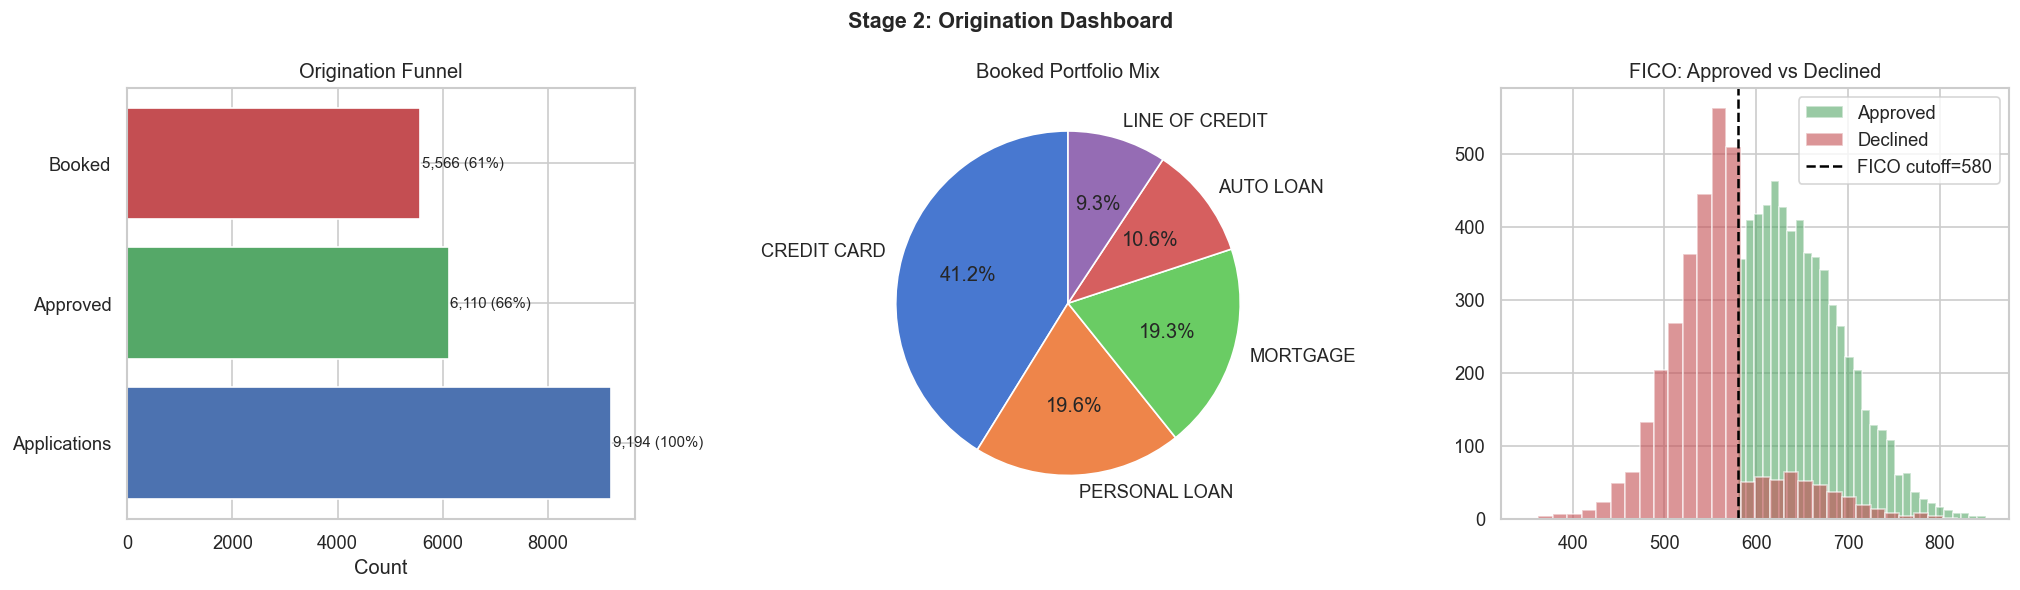

✅ Stage 2 complete


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with 3 side-by-side subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Stage 2: Origination Dashboard', fontsize=13, fontweight='bold')

# ==============================================================================
# SUBPLOT 1: Origination Funnel (Horizontal Bar Chart)
# ==============================================================================
vals   = [total_apps, total_approved, total_booked]
labels = ['Applications', 'Approved', 'Booked']
colors = ['#4C72B0', '#55A868', '#C44E52']

axes[0].barh(labels, vals, color=colors)

# Add text labels displaying values and percentages next to each bar
for i, v in enumerate(vals):
    axes[0].text(v + 30, i, f'{v:,} ({v / total_apps * 100:.0f}%)', va='center', fontsize=9)

axes[0].set_title('Origination Funnel')
axes[0].set_xlabel('Count')


# ==============================================================================
# SUBPLOT 2: Booked Portfolio Mix (Pie Chart)
# ==============================================================================
booked_mix = df_clean[df_clean['booked'] == 1]['BORROWING_TYPE'].value_counts()

axes[1].pie(
    booked_mix, 
    labels=booked_mix.index, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=sns.color_palette('muted', len(booked_mix))
)
axes[1].set_title('Booked Portfolio Mix')


# ==============================================================================
# SUBPLOT 3: FICO Score Distribution: Approved vs Declined (Histogram)
# ==============================================================================
axes[2].hist(df_clean[df_clean['approved'] == 1]['fico_score'], bins=30, alpha=0.6, color='#55A868', label='Approved')
axes[2].hist(df_clean[df_clean['approved'] == 0]['fico_score'], bins=30, alpha=0.6, color='#C44E52', label='Declined')

# Draw a vertical dashed cutoff line at FICO = 580
axes[2].axvline(580, color='black', linestyle='--', linewidth=1.5, label='FICO cutoff=580')

axes[2].set_title('FICO: Approved vs Declined')
axes[2].legend()

# Layout adjustment & saving
plt.tight_layout()
plt.savefig('stage2_origination.png', bbox_inches='tight')
plt.show()

print('✅ Stage 2 complete')

---
## 📊 Stage 3: Portfolio Performance Monitoring

Booked accounts are tracked monthly by delinquency bucket.

| Bucket | DPD | Meaning |
|--------|-----|---------|
| Current | 0 | Paying on time |
| 1–30 DPD | 1–30 | First missed payment |
| 31–60 DPD | 31–60 | Two payments missed |
| 61–90 DPD | 61–90 | Three payments missed — substandard |
| NPA | 90+ | Non-Performing Asset — RBI / IFRS9 provisioning |
| CO | 180+ | Charge-Off — written off, recovery team engaged |

**BCR = GLPA ÷ BLPA** — target ≥ 2.0 for a healthy retail book


In [25]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# STEP 1: Set random seed
# ---------------------------------------------------------

np.random.seed(42)


# ---------------------------------------------------------
# STEP 2: Keep only booked loans
# ---------------------------------------------------------


# .copy() = Make an independent copy of the selected data.

perf_df = df_clean[df_clean['booked'] == 1].copy()

# Reset the row numbers ( 0 , 1,2,3)
perf_df = perf_df.reset_index(drop=True)

# total Count booked loans
n_perf = len(perf_df)

print("Number of booked loans:", n_perf)


# ---------------------------------------------------------
# STEP 3: Calculate outstanding balance
# ---------------------------------------------------------

# Generate a random percentage between 20% and 90% for each of active lones
# n_perf tells Python how many random numbers to generate.

random_percentage = np.random.uniform(0.20, 0.90, n_perf)

# Calculate outstanding balance
perf_df['outstanding_balance'] = (
    perf_df['REQUESTED_AMOUNT'] * random_percentage
)

# Convert to whole numbers
perf_df['outstanding_balance'] = (
    perf_df['outstanding_balance'].astype(int)
)


# ---------------------------------------------------------
# STEP 4: Define delinquency categories
# ---------------------------------------------------------

buckets = [
    'Current',
    '1-30 DPD',
    '31-60 DPD',
    '61-90 DPD',
    'NPA',
    'CO'
]


# ---------------------------------------------------------
# STEP 5: Define probability for each loan product
# ---------------------------------------------------------

# This bucket_probs dictionary tells Python how likely each loan product is to fall into each delinquency category.
# The important thing is that the position of each number matches the order of your buckets list:

bucket_probs = {

    'CREDIT CARD':
    [0.60, 0.15, 0.09, 0.06, 0.05, 0.05],

    'PERSONAL LOAN':
    [0.62, 0.14, 0.09, 0.06, 0.05, 0.04],

    'MORTGAGE':
    [0.72, 0.12, 0.07, 0.04, 0.03, 0.02],

    'AUTO LOAN':
    [0.68, 0.13, 0.08, 0.05, 0.04, 0.02],

    'LINE OF CREDIT':
    [0.65, 0.13, 0.09, 0.06, 0.04, 0.03]
}


# ---------------------------------------------------------
# STEP 6: Assign delinquency category
# ---------------------------------------------------------

def get_delinquency(product):

    probability = bucket_probs[product]

# np.random.choice() randomly selects one item from your buckets.
    return np.random.choice(
        buckets,
        p=probability
    )

# .apply() means: Run this function on every value in the column.

perf_df['delinquency_bucket'] = (
    perf_df['BORROWING_TYPE'].apply(get_delinquency)
)


# ---------------------------------------------------------
# STEP 7: Convert delinquency category into DPD
# ---------------------------------------------------------
# It tells us approximately how many days the payment is overdue.
dpd_map = {

    'Current': 0,
    '1-30 DPD': 15,
    '31-60 DPD': 45,
    '61-90 DPD': 75,
    'NPA': 120,
    'CO': 200
}

# .map() looks at each value in delinquency_bucket and finds its matching value in dpd_map.
# dpd_map converts each delinquency category into a representative number of days overdue, and .map() applies that conversion to every loan.

perf_df['dpd'] = (
    perf_df['delinquency_bucket'].map(dpd_map)
)


# ---------------------------------------------------------
# STEP 8: Calculate GLPA
# ---------------------------------------------------------
# why we calculate GLPA :-How much outstanding loan balance is currently in the relatively healthier categories?

good_loans = (
    perf_df['delinquency_bucket'] == 'Current'
) | (
    perf_df['delinquency_bucket'] == '1-30 DPD'
)
#  .loc[] is used to select specific rows and columns.

glpa = perf_df.loc[
    good_loans,
    'outstanding_balance'
].sum()


# ---------------------------------------------------------
# STEP 9: Calculate BLPA
# ---------------------------------------------------------
# BLPA is the total outstanding balance of loans that are in the more serious delinquency categories: 61-90 DPD, NPA, and CO.

bad_loans = (
    perf_df['delinquency_bucket'] == '61-90 DPD'
) | (
    perf_df['delinquency_bucket'] == 'NPA'
) | (
    perf_df['delinquency_bucket'] == 'CO'
)

blpa = perf_df.loc[
    bad_loans,
    'outstanding_balance'
].sum()


# ---------------------------------------------------------
# STEP 10: Calculate BCR
# ---------------------------------------------------------
# to compare the good/healthier balance against the bad/high-risk balance.

bcr = glpa / blpa


# ---------------------------------------------------------
# STEP 11: Display performance KPIs
# ---------------------------------------------------------

print()
print("📊 PERFORMANCE KPIs")

print("Booked Accounts:", n_perf)

print(
    "GLPA: ₹",
    round(glpa / 1e7, 2),
    "Cr"
)

print(
    "BLPA: ₹",
    round(blpa / 1e7, 2),
    "Cr"
)

print(
    "BCR:",
    round(bcr, 2),
    "x"
)

if bcr >= 2:
    print("Status: ✅ Healthy")
else:
    print("Status: ⚠️ Watch List")


# ---------------------------------------------------------
# STEP 12: Product / delinquency summary
# ---------------------------------------------------------

bkt = perf_df.groupby(
    'delinquency_bucket'
).agg(
    Accounts=('APPLICATION_NUMBER', 'count'),
    Balance=('outstanding_balance', 'sum')
)


# Put categories in our desired order
bkt = bkt.reindex(buckets)


# Calculate percentage of accounts
bkt['Accounts%'] = (
    bkt['Accounts'] / n_perf * 100
).round(1)


# Convert balance into Crores
bkt['Balance_Cr'] = (
    bkt['Balance'] / 1e7
).round(2)


# Display only the required columns
bkt = bkt[
    ['Accounts', 'Accounts%', 'Balance_Cr']
]


print()
print("📋 Delinquency Summary")
print(bkt)

Number of booked loans: 5566

📊 PERFORMANCE KPIs
Booked Accounts: 5566
GLPA: ₹ 725.37 Cr
BLPA: ₹ 95.72 Cr
BCR: 7.58 x
Status: ✅ Healthy

📋 Delinquency Summary
                    Accounts  Accounts%  Balance_Cr
delinquency_bucket                                 
Current                 3629       65.2      626.93
1-30 DPD                 736       13.2       98.45
31-60 DPD                468        8.4       71.89
61-90 DPD                308        5.5       42.46
NPA                      239        4.3       31.88
CO                       186        3.3       21.37


Booked Accounts

      ↓
How many loans were booked?

GLPA

      ↓
How much balance is in healthier categories?

BLPA

      ↓
How much balance is in higher-risk categories?

BCR

      ↓

How much larger is GLPA compared with BLPA?

Status

      ↓

Healthy or Watch List

In [26]:
glpa

np.int64(7253729656)

In [27]:
blpa

np.int64(957184744)

In [28]:
perf_df['outstanding_balance']   # total outstanding balance of all booked loans

0        143275
1        276960
2         85487
3        253814
4       2486072
         ...   
5561     252653
5562     677748
5563     175403
5564    1057978
5565      96985
Name: outstanding_balance, Length: 5566, dtype: int64

In [29]:

perf_df.to_csv('perf_bucket.csv', index=False)
perf_df


,APPLICATION_NUMBER,CUSTOMER_NUMBER,APPLICATION_DATE,BORROWING_TYPE,REQUESTED_AMOUNT,TENURE,AGE,Gender,Region,State,...,income_monthly,existing_loans,monthly_debt,tdi,ltv,approved,booked,outstanding_balance,delinquency_bucket,dpd
0,324511199,959111000,2016-01-08 05:30:00+05:30,CREDIT CARD,310000.0,3.0,50,F,South,OK,...,258333,0,0,0.0,0.50,1,1,143275,1-30 DPD,15
1,324511200,959111001,2016-02-16 05:30:00+05:30,PERSONAL LOAN,320000.0,3.0,62,F,Northeast,NY,...,266666,1,26666,0.1,0.50,1,1,276960,1-30 DPD,15
2,324511201,959111002,2016-04-24 05:30:00+05:30,CREDIT CARD,120000.0,3.0,33,M,West,UT,...,100000,0,0,0.0,0.50,1,1,85487,31-60 DPD,45
3,324511202,959111003,2020-08-28 05:30:00+05:30,CREDIT CARD,410000.0,3.0,44,F,Midwest,OH,...,341666,0,0,0.0,0.50,1,1,253814,CO,200
4,324511203,959111004,2018-01-24 05:30:00+05:30,MORTGAGE,8040000.0,22.0,50,F,Midwest,IL,...,913636,3,274090,0.3,0.42,1,1,2486072,NPA,120
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5561,324521300,959116997,2016-11-06 05:30:00+05:30,CREDIT CARD,281235.0,3.0,61,M,West,MT,...,234362,1,23436,0.1,0.50,1,1,252653,Current,0
5562,324521301,959116998,2016-02-03 05:30:00+05:30,AUTO LOAN,1762740.0,3.0,44,M,South,GA,...,1468950,3,440685,0.3,0.76,1,1,677748,Current,0
5563,324521302,959116999,2019-04-02 05:30:00+05:30,CREDIT CARD,443621.0,3.0,50,M,South,MD,...,369684,2,73936,0.2,0.50,1,1,175403,61-90 DPD,75
5564,324521305,959117000,2020-04-20 05:30:00+05:30,PERSONAL LOAN,1242531.0,7.0,48,M,Northeast,PA,...,443761,1,44376,0.1,0.50,1,1,1057978,31-60 DPD,45


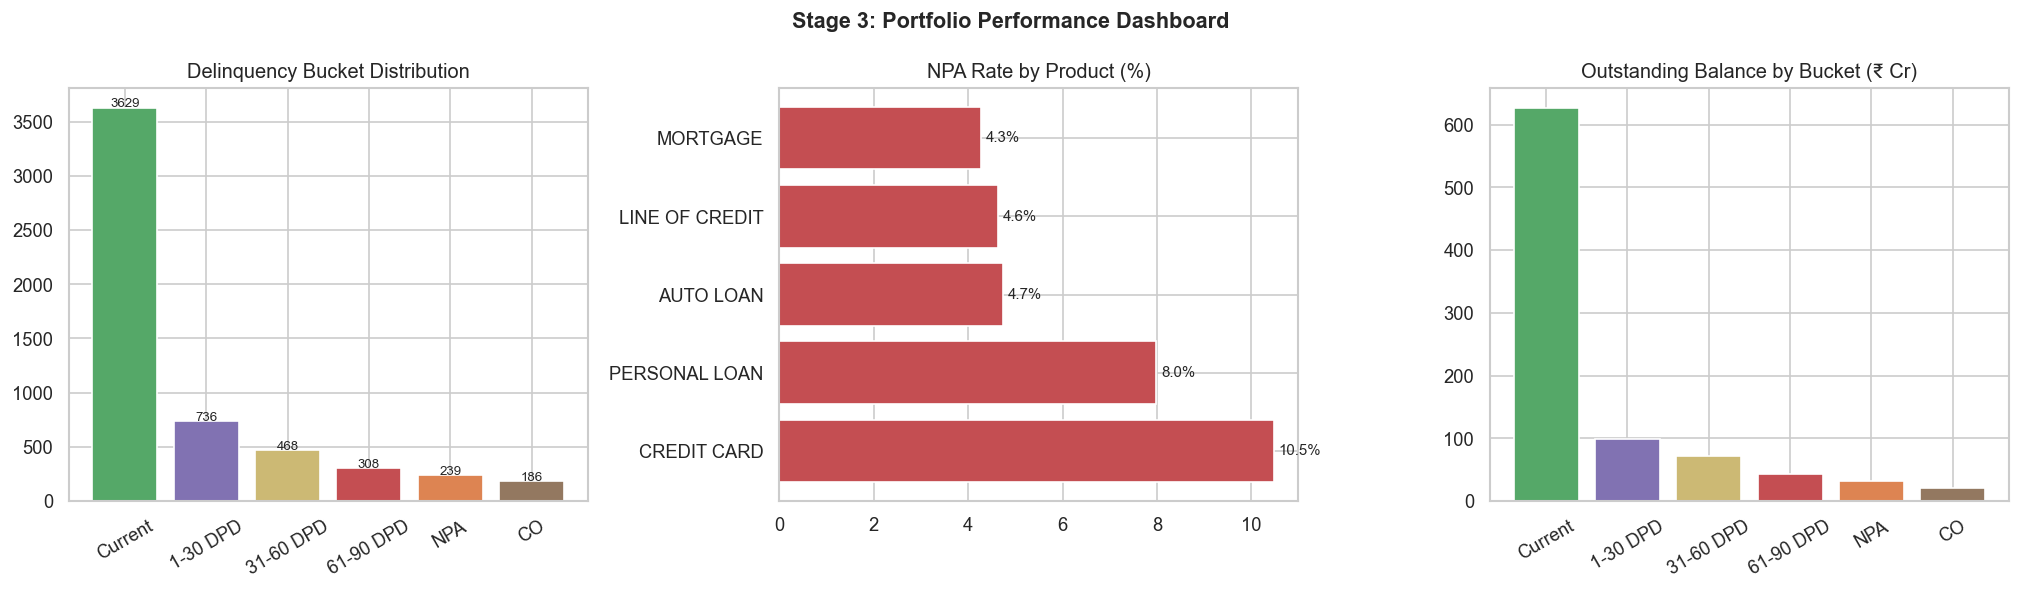

✅ Stage 3 complete


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Stage 3: Portfolio Performance Dashboard', fontsize=13, fontweight='bold')

bucket_colors = ['#55A868','#8172B2','#CCB974','#C44E52','#DD8452','#937860']
bkt_counts = perf_df['delinquency_bucket'].value_counts().reindex(buckets)
axes[0].bar(buckets, bkt_counts, color=bucket_colors, edgecolor='white')
axes[0].set_title('Delinquency Bucket Distribution')
axes[0].tick_params(axis='x', rotation=30)
for i,v in enumerate(bkt_counts): axes[0].text(i, v+5, str(v), ha='center', fontsize=8)

npa_rate = (
    perf_df.groupby('BORROWING_TYPE')
    .apply(lambda x: (x['delinquency_bucket'].isin(['NPA','CO'])).mean()*100)
    .sort_values(ascending=False)
)
axes[1].barh(npa_rate.index, npa_rate.values, color='#C44E52', edgecolor='white')
axes[1].set_title('NPA Rate by Product (%)')
for i,v in enumerate(npa_rate.values): axes[1].text(v+0.1, i, f'{v:.1f}%', va='center', fontsize=9)

bkt_bal = perf_df.groupby('delinquency_bucket')['outstanding_balance'].sum().reindex(buckets)/1e7
axes[2].bar(buckets, bkt_bal, color=bucket_colors, edgecolor='white')
axes[2].set_title('Outstanding Balance by Bucket (₹ Cr)')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('stage3_performance.png', bbox_inches='tight')
plt.show()
print('✅ Stage 3 complete')


---
## 🤖 Stage 4: ML Model — Probability of Default (PD)

Two models trained on real customer + application features:

1. **Logistic Regression** — interpretable, regulator-friendly (coefficients = auditable)
2. **Random Forest** — higher AUC, captures non-linear patterns

**IFRS9 Expected Loss:** EL = PD × EAD × LGD  
LGD is **product-specific** (Mortgage 20% vs Credit Card 75%) — not a flat 45%


In [31]:
# ---------------------------------------------------------
# STEP 1: Create a default column
# ---------------------------------------------------------


# interview:- We have loan account data, and we want to identify which loans are defaulted and then count the total loans and total defaults.
# NPA and CO are considered defaults
# creates a new column called is_default and puts 0 for every loan initially.
# .isin() checks whether each value is present in the list:
# 0 = Not Default
# 1 = Default
# "First assume every loan is not a default. Then, if the loan is classified as NPA or CO, mark it as a default."


perf_df['is_default'] = 0

perf_df.loc[
    perf_df['delinquency_bucket'].isin(['NPA', 'CO']),
    'is_default'
] = 1


# ---------------------------------------------------------
# STEP 2: Count total accounts
# ---------------------------------------------------------

total_accounts = len(perf_df)

print("Total Accounts:", total_accounts)


# ---------------------------------------------------------
# STEP 3: Count total defaults
# ---------------------------------------------------------

total_defaults = perf_df['is_default'].sum()

print("Total Defaults:", total_defaults)


# ---------------------------------------------------------
# STEP 4: Calculate default rate
# ---------------------------------------------------------


# Default Rate = (Total Defaults ÷ Total Accounts) × 100
# round the result to 1 decimal place for easier reading.( ex- 8.3476 then its give 8.3)
# interview:- I calculated the default rate by dividing the total number of defaulted accounts by the total number of accounts and multiplying by 100. 
# This gives me the percentage of accounts that are in default and helps me understand the overall portfolio risk.”


default_rate = (
    total_defaults / total_accounts
) * 100

print(
    "Default Rate:",
    round(default_rate, 1),
    "%"
)


# ---------------------------------------------------------
# STEP 5: Default rate by product
# ---------------------------------------------------------

# groupby('BORROWING_TYPE') It groups your loans according to their product type.
# interview:- “I grouped the loan accounts by borrowing type and calculated the average of the is_default flag for each product.
# Since is_default contains 0 and 1, the mean gives the default rate.
# I then converted it into a percentage and rounded it to one decimal place.”

print()
print("Default Rate by Product:")


# Group loans by product
product_default_rate = (
    perf_df.groupby('BORROWING_TYPE')['is_default']
    .mean()
)


# Convert rate into percentage
product_default_rate = product_default_rate * 100


# Round to 1 decimal place
product_default_rate = product_default_rate.round(1)


print(product_default_rate)

Total Accounts: 5566
Total Defaults: 425
Default Rate: 7.6 %

Default Rate by Product:
BORROWING_TYPE
AUTO LOAN          4.7
CREDIT CARD       10.5
LINE OF CREDIT     4.6
MORTGAGE           4.3
PERSONAL LOAN      8.0
Name: is_default, dtype: float64


     Booked Loans
        ↓
     Check Delinquency
         ↓
     NPA or CO?
       ↙       ↘
      Yes        No
       ↓          ↓
     Default=1  Default=0
          ↓
     Calculate Default Rate
          ↓
     Overall + Product-wise

In [32]:
perf_df
perf_df.to_csv('df_is_default.csv', index=False)


In [33]:
# ---------------------------------------------------------
# STEP 1: Make a copy of the performance data
# ---------------------------------------------------------

ml_df = perf_df.copy()


# ---------------------------------------------------------
# STEP 2: Convert text columns into numbers
# ---------------------------------------------------------

# machine-learning models need numerical inputs, but columns like product, gender, and region contain text. So we convert those categories into numbers.


# interview:- “Before building the machine learning model, I converted categorical variables such as borrowing type, gender,
# and region into numerical values using LabelEncoder. 
# I created separate encoded columns while keeping the original columns unchanged. 
# This made the categorical information suitable for machine learning.”




from sklearn.preprocessing import LabelEncoder

# LabelEncoder converts text categories into numbers.
le = LabelEncoder()


# Convert BORROWING_TYPE into numbers
# product_enc = numerical version of BORROWING_TYPE
ml_df['product_enc'] = le.fit_transform(
    ml_df['BORROWING_TYPE']
)

# fit → learns the unique categories.
# transform → converts those categories into numbers.
# Convert Gender into numbers

ml_df['gender_enc'] = le.fit_transform(
    ml_df['Gender']
)


# Convert Region into numbers
ml_df['region_enc'] = le.fit_transform(
    ml_df['Region']
)


# ---------------------------------------------------------
# STEP 3: Select input columns for ML
# ---------------------------------------------------------

# This step is where you select the variables that the machine-learning model will use to predict default.
# Here, features is simply a list of input columns that you want to give to the ML model.

features = [
    'fico_score',
    'tdi',
    'income_monthly',
    'REQUESTED_AMOUNT',
    'ltv',
    'AGE',
    'existing_loans',
    'outstanding_balance',
    'TENURE',
    'product_enc',
    'gender_enc',
    'region_enc'
]


# ---------------------------------------------------------
# STEP 4: Create X and y
# ---------------------------------------------------------

# interview:- I selected relevant customer and loan-related variables such as 
# FICO score, TDI, income, requested amount, LTV, existing loans, outstanding balance, tenure, and 
# encoded categorical variables as my input features. I stored these features in X.
# The target variable was is_default, where 1 represents default and 0 represents non-default, and I stored it in y.”

# X = What the model uses to make a prediction.
# y = What the model is trying to predict.
#Or in your banking project:
# X = Customer + loan risk factors
# y = Default or non-default

# This selects all the columns mentioned in your features list.
# So X contains the information that the model will learn from.
# X = Input variables / independent variables

X = ml_df[features]

# y contains what you want the model to predict.
# y = Target / output variable
y = ml_df['is_default']


# ---------------------------------------------------------
# STEP 5: Split data into training and testing
# ---------------------------------------------------------


# This step has two important parts:
# Split your data into training and testing data
# Scale the input variables using StandardScaler



from sklearn.model_selection import train_test_split

# 80% → Training data
# 20% → Testing data


# This is very important for your credit-risk project. (stratify=y)

# (stratify=y) :- makes sure the training and testing datasets have approximately the same proportion of defaults and non-defaults as the original dataset.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------------
# STEP 6: Scale the input variables
# ---------------------------------------------------------

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


# Learn scaling values from training data
# and scale training data
X_train_scaled = scaler.fit_transform(X_train)


# Use the same scaling values for test data
X_test_scaled = scaler.transform(X_test)


# ---------------------------------------------------------
# STEP 7: Display training and testing information
# ---------------------------------------------------------

print(
    "Training Accounts:",
    len(X_train)
)

print(
    "Testing Accounts:",
    len(X_test)
)

print(
    "Training Default Rate:",
    round(y_train.mean() * 100, 1),
    "%"
)

print(
    "Testing Default Rate:",
    round(y_test.mean() * 100, 1),
    "%"
)



# interview :- “I split the data into 80% training and 20% testing using train_test_split.
# I used random_state=42 for reproducibility and stratify=y to maintain the same default and non-default proportion in both datasets. 
# After splitting, I applied StandardScaler. I fitted the scaler only on the training data and used the same scaling parameters 
# to transform the test data. This helps prevent data leakage.”



Training Accounts: 4452
Testing Accounts: 1114
Training Default Rate: 7.6 %
Testing Default Rate: 7.6 %


          PERFORMANCE DATA
               ↓
          Create is_default
               ↓
          Select ML features
               ↓
               X ───────────────┐
                              │
               y = is_default   │
                              ↓
                         Train/Test Split
                         ↙️          ↘️
                    80% Training   20% Testing
                         ↓              ↓
                    Scaling          Scaling
                         ↓              ↓
                    X_train_scaled  X_test_scaled
                         ↓
                    Train ML Model
                         ↓
                    Logistic Regression
                    / Random Forest
                         ↓
                    Predict PD


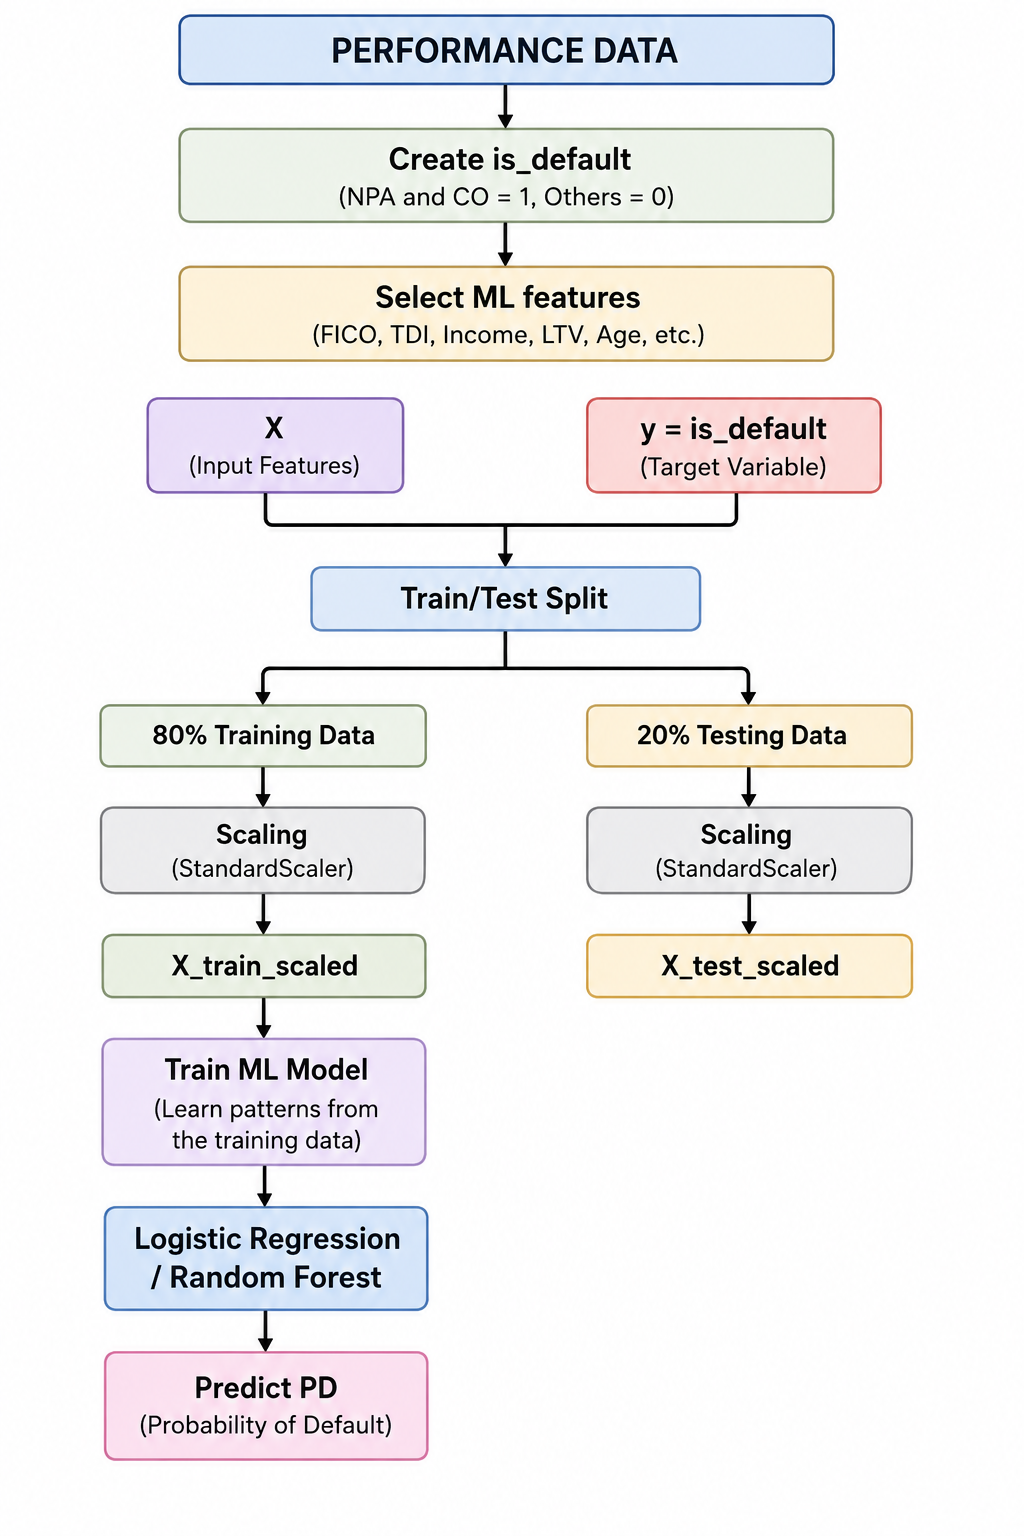

In [34]:

ml_df.to_csv('df_ml.csv', index=False)
ml_df



,APPLICATION_NUMBER,CUSTOMER_NUMBER,APPLICATION_DATE,BORROWING_TYPE,REQUESTED_AMOUNT,TENURE,AGE,Gender,Region,State,...,ltv,approved,booked,outstanding_balance,delinquency_bucket,dpd,is_default,product_enc,gender_enc,region_enc
0,324511199,959111000,2016-01-08 05:30:00+05:30,CREDIT CARD,310000.0,3.0,50,F,South,OK,...,0.50,1,1,143275,1-30 DPD,15,0,1,0,2
1,324511200,959111001,2016-02-16 05:30:00+05:30,PERSONAL LOAN,320000.0,3.0,62,F,Northeast,NY,...,0.50,1,1,276960,1-30 DPD,15,0,4,0,1
2,324511201,959111002,2016-04-24 05:30:00+05:30,CREDIT CARD,120000.0,3.0,33,M,West,UT,...,0.50,1,1,85487,31-60 DPD,45,0,1,1,4
3,324511202,959111003,2020-08-28 05:30:00+05:30,CREDIT CARD,410000.0,3.0,44,F,Midwest,OH,...,0.50,1,1,253814,CO,200,1,1,0,0
4,324511203,959111004,2018-01-24 05:30:00+05:30,MORTGAGE,8040000.0,22.0,50,F,Midwest,IL,...,0.42,1,1,2486072,NPA,120,1,3,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5561,324521300,959116997,2016-11-06 05:30:00+05:30,CREDIT CARD,281235.0,3.0,61,M,West,MT,...,0.50,1,1,252653,Current,0,0,1,1,4
5562,324521301,959116998,2016-02-03 05:30:00+05:30,AUTO LOAN,1762740.0,3.0,44,M,South,GA,...,0.76,1,1,677748,Current,0,0,0,1,2
5563,324521302,959116999,2019-04-02 05:30:00+05:30,CREDIT CARD,443621.0,3.0,50,M,South,MD,...,0.50,1,1,175403,61-90 DPD,75,0,1,1,2
5564,324521305,959117000,2020-04-20 05:30:00+05:30,PERSONAL LOAN,1242531.0,7.0,48,M,Northeast,PA,...,0.50,1,1,1057978,31-60 DPD,45,0,4,1,1


      Loan data
            ↓
     Convert text to numbers
            ↓
      Select features
           ↓
      Separate X and y
            ↓
     Split into training/testing data
            ↓
     Scale the features
            ↓
     Ready for ML model

In [35]:
%pip install lightgbm shap


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [38]:
# =========================================================
# STEP 1: IMPORT LIBRARIES
# =========================================================
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, classification_report
import pandas as pd

# =========================================================
# STEP 2: LOGISTIC REGRESSION (CHAMPION)
# =========================================================
# Create and train Logistic Regression model
lr = LogisticRegression(
    max_iter=500,
    random_state=42,
    class_weight='balanced'
)
lr.fit(X_train_scaled, y_train)

# Predictions and Probability of Default
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

# Calculate AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)

print("🔵 LOGISTIC REGRESSION")
print("AUC Score:", round(auc_lr, 3))
print(classification_report(y_test, y_pred_lr, target_names=['Non-Default', 'Default']))

# =========================================================
# STEP 3: LIGHTGBM (CHALLENGER - REPLACING RANDOM FOREST)
# =========================================================
# Create and train LightGBM model
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

# Predictions and Probability of Default
y_pred_lgb = lgb_model.predict(X_test)
y_prob_lgb = lgb_model.predict_proba(X_test)[:, 1]

# Calculate AUC
auc_lgb = roc_auc_score(y_test, y_prob_lgb)

print("🟢 LIGHTGBM")
print("AUC Score:", round(auc_lgb, 3))
print(classification_report(y_test, y_pred_lgb, target_names=['Non-Default', 'Default']))

# =========================================================
# STEP 4: MODEL COMPARISON
# =========================================================
print("🏆 MODEL COMPARISON")
if auc_lgb > auc_lr:
    winner = "LightGBM"
    difference = auc_lgb - auc_lr
else:
    winner = "Logistic Regression"
    difference = auc_lr - auc_lgb

print("Best Model:", winner)
print("AUC Difference:", round(difference, 3))

🔵 LOGISTIC REGRESSION
AUC Score: 0.53
              precision    recall  f1-score   support

 Non-Default       0.93      0.55      0.69      1029
     Default       0.08      0.51      0.14        85

    accuracy                           0.54      1114
   macro avg       0.51      0.53      0.42      1114
weighted avg       0.87      0.54      0.65      1114

🟢 LIGHTGBM
AUC Score: 0.531
              precision    recall  f1-score   support

 Non-Default       0.93      0.81      0.86      1029
     Default       0.08      0.21      0.12        85

    accuracy                           0.76      1114
   macro avg       0.50      0.51      0.49      1114
weighted avg       0.86      0.76      0.81      1114

🏆 MODEL COMPARISON
Best Model: LightGBM
AUC Difference: 0.001


----

Precision

Out of the accounts predicted as default, how many were actually default?

Recall

Out of all actual defaults, how many did the model correctly identify?

F1-score

Combination of precision and recall.

Support

Number of actual observations in each class.

        Clean Data
            ↓
        Create Features
            ↓
        Create is_default
            ↓
        Train/Test Split
            ↓
            ┌──────────────────┐
            ↓                  ↓
        Logistic Regression   Random Forest
            ↓                  ↓
            AUC                AUC
            ↓                  ↓
            └────── Compare ───┘
                    ↓
                Best Model

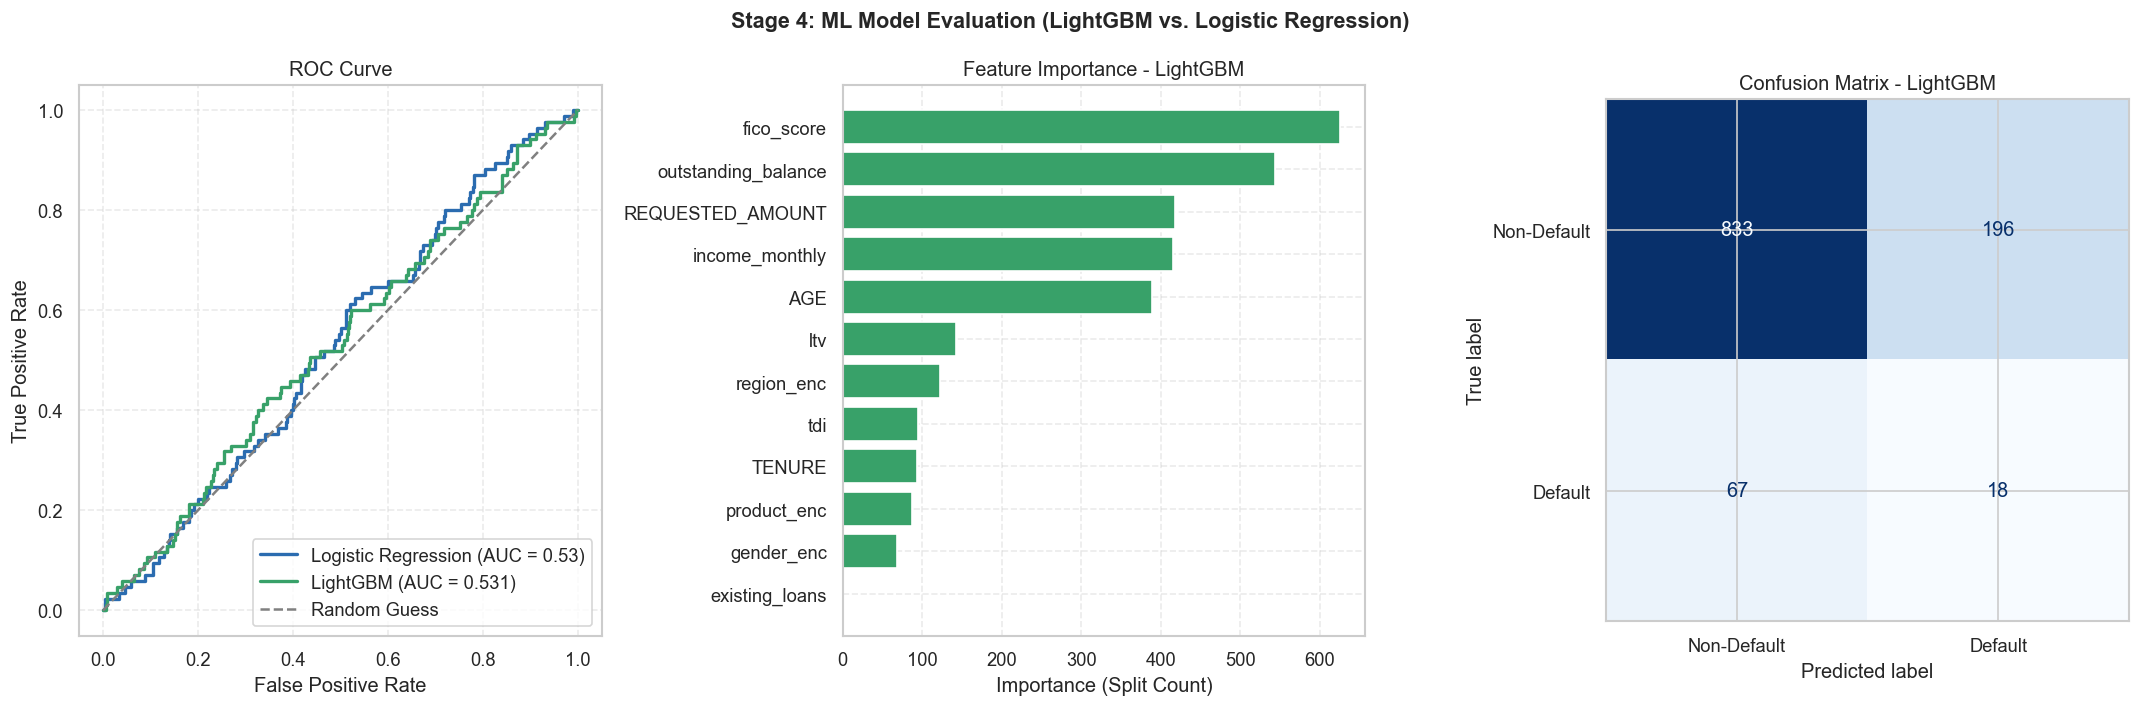

In [40]:
# =========================================================
# STEP 1: IMPORT LIBRARIES
# =========================================================
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay

# =========================================================
# STEP 2: CREATE 3 CHARTS
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plt.suptitle("Stage 4: ML Model Evaluation (LightGBM vs. Logistic Regression)", fontsize=13, fontweight="bold")

# ---------------------------------------------------------
# CHART 1: ROC CURVE COMPARISON
# ---------------------------------------------------------
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_prob_lgb)

axes[0].plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {round(auc_lr, 3)})", color="#2B6CB0", lw=2)
axes[0].plot(fpr_lgb, tpr_lgb, label=f"LightGBM (AUC = {round(auc_lgb, 3)})", color="#38A169", lw=2)
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random Guess")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.4)

# ---------------------------------------------------------
# CHART 2: FEATURE IMPORTANCE (LIGHTGBM)
# ---------------------------------------------------------
importance = lgb_model.feature_importances_
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values("Importance")

axes[1].barh(feature_importance["Feature"], feature_importance["Importance"], color="#38A169")
axes[1].set_title("Feature Importance - LightGBM")
axes[1].set_xlabel("Importance (Split Count)")
axes[1].grid(True, linestyle="--", alpha=0.4)

# ---------------------------------------------------------
# CHART 3: CONFUSION MATRIX (LIGHTGBM)
# ---------------------------------------------------------
cm = confusion_matrix(y_test, y_pred_lgb)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Default", "Default"])
display.plot(ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title("Confusion Matrix - LightGBM")

# =========================================================
# FINAL DISPLAY & SAVE
# =========================================================
plt.tight_layout()
plt.savefig("stage4_ml.png", bbox_inches="tight")
plt.show()

                    ML Models
                        ↓
            ┌───────────┼───────────┐
            ↓           ↓           ↓
        ROC Curve   Feature      Confusion
                    Importance     Matrix
            ↓           ↓           ↓
        Model       Important    Correct &
        Quality     Features     Wrong Predictions

## 🔄 Stage 5: Capital Risk & Expected loss(EL) Calculation

-----
The basic IFRS 9 Expected Credit Loss formula is:

Expected Loss = PD × EAD × LGD

In [42]:
# LGD = Loss Given Default
# It represents the percentage of money expected to be lost if a customer defaults.
lgd_map = {
    'MORTGAGE': 0.20,
    'AUTO LOAN': 0.35,
    'LINE OF CREDIT': 0.55,
    'PERSONAL LOAN': 0.65,
    'CREDIT CARD': 0.75
}

# ---------------------------------------------------------
# STEP 2: Calculate Probability of Default (PD)
# ---------------------------------------------------------
# Use LightGBM to predict probability of default
perf_df['pd_score'] = lgb_model.predict_proba(ml_df[features])[:, 1]

# ---------------------------------------------------------
# STEP 3: Calculate Exposure at Default (EAD)
# ---------------------------------------------------------
# In this project, we use the outstanding balance as the Exposure at Default.
perf_df['ead'] = perf_df['outstanding_balance']

# ---------------------------------------------------------
# STEP 4: Assign LGD to each loan
# ---------------------------------------------------------
# Match each loan product with its LGD value
perf_df['lgd'] = perf_df['BORROWING_TYPE'].map(lgd_map)

# ---------------------------------------------------------
# STEP 5: Calculate Expected Loss
# ---------------------------------------------------------
# Formula: Expected Loss = PD × EAD × LGD
perf_df['EL'] = perf_df['pd_score'] * perf_df['ead'] * perf_df['lgd']

# ---------------------------------------------------------
# STEP 6: Calculate total Expected Loss
# ---------------------------------------------------------
total_expected_loss = perf_df['EL'].sum()

# ---------------------------------------------------------
# STEP 7: Calculate total outstanding balance
# ---------------------------------------------------------
total_outstanding = perf_df['ead'].sum()

# ---------------------------------------------------------
# STEP 8: Calculate Expected Loss percentage
# ---------------------------------------------------------
expected_loss_percentage = (total_expected_loss / total_outstanding) * 100

# ---------------------------------------------------------
# STEP 9: Print overall results
# ---------------------------------------------------------
print("💰 EXPECTED LOSS RESULTS")
print("Total Expected Loss: ₹", round(total_expected_loss / 1e7, 2), "Crore")
print("Expected Loss as % of Outstanding:", round(expected_loss_percentage, 2), "%")

# ---------------------------------------------------------
# STEP 10: Calculate Expected Loss by Product
# ---------------------------------------------------------
print()
print("📊 Expected Loss by Product:")

product_summary = perf_df.groupby('BORROWING_TYPE').agg(
    # Total outstanding balance
    EAD=('ead', 'sum'),
    # Total Expected Loss
    Expected_Loss=('EL', 'sum'),
    # Average Probability of Default
    Average_PD=('pd_score', 'mean'),
    # LGD for the product
    LGD=('lgd', 'first')
)

# ---------------------------------------------------------
# STEP 11: Convert amounts into Crores
# ---------------------------------------------------------
product_summary['EAD_Crore'] = (product_summary['EAD'] / 1e7).round(2)
product_summary['EL_Crore'] = (product_summary['Expected_Loss'] / 1e7).round(2)

# ---------------------------------------------------------
# STEP 12: Calculate Expected Loss percentage
# ---------------------------------------------------------
product_summary['EL_Percentage'] = (
    product_summary['EL_Crore'] / product_summary['EAD_Crore']
) * 100
product_summary['EL_Percentage'] = product_summary['EL_Percentage'].round(1)

# ---------------------------------------------------------
# STEP 13: Display final product-wise results
# ---------------------------------------------------------
print(
    product_summary[
        [
            'EAD_Crore',
            'EL_Crore',
            'Average_PD',
            'LGD',
            'EL_Percentage'
        ]
    ].round(3)
)

print()
print("✅ Expected Loss calculation complete with LightGBM")

💰 EXPECTED LOSS RESULTS
Total Expected Loss: ₹ 80.76 Crore
Expected Loss as % of Outstanding: 9.04 %

📊 Expected Loss by Product:
                EAD_Crore  EL_Crore  Average_PD   LGD  EL_Percentage
BORROWING_TYPE                                                      
AUTO LOAN           45.17      3.02       0.204  0.35            6.7
CREDIT CARD        119.72     37.01       0.430  0.75           30.9
LINE OF CREDIT       8.86      1.15       0.215  0.55           13.0
MORTGAGE           654.19     27.20       0.185  0.20            4.2
PERSONAL LOAN       65.04     12.38       0.299  0.65           19.0

✅ Expected Loss calculation complete with LightGBM


# Why does .sum() work?

Because:

0 = No default → adds nothing

1 = Default    → adds one

---

Performance Data

       ↓

Check delinquency bucket

       ↓

NPA / CO → is_default = 1
Others   → is_default = 0

                ↓


       ┌──────────────────────┐

       ↓                      ↓


Total Accounts          Total Defaults

       ↓                      ↓
       
   5,000 accounts         400 defaults

----

1. First understand the main idea

In credit risk, the bank wants to answer:

“How much money might we lose from our current loans because some customers may default?”

The basic IFRS 9 Expected Credit Loss formula is:

Expected Loss = PD × EAD × LGD

In [43]:
perf_df.to_csv('df_creditrisk.csv', index=False)
perf_df

,APPLICATION_NUMBER,CUSTOMER_NUMBER,APPLICATION_DATE,BORROWING_TYPE,REQUESTED_AMOUNT,TENURE,AGE,Gender,Region,State,...,approved,booked,outstanding_balance,delinquency_bucket,dpd,is_default,pd_score,ead,lgd,EL
0,324511199,959111000,2016-01-08 05:30:00+05:30,CREDIT CARD,310000.0,3.0,50,F,South,OK,...,1,1,143275,1-30 DPD,15,0,0.389111,143275,0.75,41812.356755
1,324511200,959111001,2016-02-16 05:30:00+05:30,PERSONAL LOAN,320000.0,3.0,62,F,Northeast,NY,...,1,1,276960,1-30 DPD,15,0,0.306498,276960,0.65,55177.060068
2,324511201,959111002,2016-04-24 05:30:00+05:30,CREDIT CARD,120000.0,3.0,33,M,West,UT,...,1,1,85487,31-60 DPD,45,0,0.495522,85487,0.75,31770.534315
3,324511202,959111003,2020-08-28 05:30:00+05:30,CREDIT CARD,410000.0,3.0,44,F,Midwest,OH,...,1,1,253814,CO,200,1,0.698436,253814,0.75,132954.711373
4,324511203,959111004,2018-01-24 05:30:00+05:30,MORTGAGE,8040000.0,22.0,50,F,Midwest,IL,...,1,1,2486072,NPA,120,1,0.095495,2486072,0.20,47481.613099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5561,324521300,959116997,2016-11-06 05:30:00+05:30,CREDIT CARD,281235.0,3.0,61,M,West,MT,...,1,1,252653,Current,0,0,0.557072,252653,0.75,105559.504248
5562,324521301,959116998,2016-02-03 05:30:00+05:30,AUTO LOAN,1762740.0,3.0,44,M,South,GA,...,1,1,677748,Current,0,0,0.119871,677748,0.35,28434.901689
5563,324521302,959116999,2019-04-02 05:30:00+05:30,CREDIT CARD,443621.0,3.0,50,M,South,MD,...,1,1,175403,61-90 DPD,75,0,0.688757,175403,0.75,90607.538339
5564,324521305,959117000,2020-04-20 05:30:00+05:30,PERSONAL LOAN,1242531.0,7.0,48,M,Northeast,PA,...,1,1,1057978,31-60 DPD,45,0,0.212021,1057978,0.65,145803.779669


---
## 🔄 Stage 6: Recovery Metrics

After Charge-Off, the collections team works the account.  
Recovery probability varies by product — secured products (Mortgage, Auto) recover more.


----
The main idea is:

Take CO accounts → check who paid → calculate recovered money → calculate Pay Rate and Recovery Rate → prioritize accounts → show recovery by product.

In [44]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# STEP 1: Select Charge-Off accounts
# ---------------------------------------------------------

np.random.seed(42)

co = perf_df[perf_df['delinquency_bucket'] == 'CO'].copy()

print("Charge-Off Accounts:", len(co))

print(
    "Total CO Balance:",
    round(co['outstanding_balance'].sum() / 1e7, 2),
    "Crore"
)


# ---------------------------------------------------------
# STEP 2: Define recovery probability by product
# ---------------------------------------------------------

recovery_prob = {
    'MORTGAGE': 0.75,
    'AUTO LOAN': 0.68,
    'LINE OF CREDIT': 0.55,
    'PERSONAL LOAN': 0.50,
    'CREDIT CARD': 0.45
}


# ---------------------------------------------------------
# STEP 3: Check whether customer paid
# ---------------------------------------------------------

co['paid'] = 0

for i in co.index:

    product = co.loc[i, 'BORROWING_TYPE']

    probability = recovery_prob.get(product, 0.55)

    co.loc[i, 'paid'] = np.random.binomial(
        1,
        probability
    )


# ---------------------------------------------------------
# STEP 4: Calculate recovered amount
# ---------------------------------------------------------

co['recovered'] = 0.0

for i in co.index:

    if co.loc[i, 'paid'] == 1:

        balance = co.loc[i, 'outstanding_balance']

        recovery_percentage = np.random.uniform(
            0.30,
            0.90
        )

        co.loc[i, 'recovered'] = (
            balance * recovery_percentage
        )


# ---------------------------------------------------------
# STEP 5: Calculate Pay Rate
# ---------------------------------------------------------

print(f'\n📊 RECOVERY KPIs')

pay_rate = co['paid'].mean() * 100

print()
print("Pay Rate:", round(pay_rate, 1), "%")


# ---------------------------------------------------------
# STEP 6: Calculate Recovery Rate
# ---------------------------------------------------------

total_recovered = co['recovered'].sum()

total_balance = co['outstanding_balance'].sum()

recovery_rate = (
    total_recovered / total_balance
) * 100

print(
    "Recovery Rate:",
    round(recovery_rate, 1),
    "%"
)


# ---------------------------------------------------------
# STEP 7: Create Collection Risk Score
# ---------------------------------------------------------

balance_score = (
    co['outstanding_balance']
    / co['outstanding_balance'].max()
)

fico_risk = (
    (850 - co['fico_score'])
    / (850 - 300)
)

co['risk_score'] = (
    balance_score * 0.6
    +
    fico_risk * 0.4
)


# ---------------------------------------------------------
# STEP 8: Create Collection Priority
# ---------------------------------------------------------

co['priority'] = pd.qcut(
    co['risk_score'],
    q=3,
    labels=[
        'LOW',
        'MEDIUM',
        'HIGH'
    ]
)


# ---------------------------------------------------------
# STEP 9: Recovery by Product
# ---------------------------------------------------------

print()
print("Recovery by Product:")

rec = co.groupby('BORROWING_TYPE').agg(

    CO_Accounts=(
        'APPLICATION_NUMBER',
        'count'
    ),

    Balance_Lakhs=(
        'outstanding_balance',
        lambda x: x.sum() / 1e5
    ),

    Recovered_Lakhs=(
        'recovered',
        lambda x: x.sum() / 1e5
    ),

    Pay_Rate=(
        'paid',
        lambda x: x.mean() * 100
    )
)


# ---------------------------------------------------------
# STEP 10: Calculate Recovery %
# ---------------------------------------------------------

rec['Recovery_Rate'] = (
    rec['Recovered_Lakhs']
    / rec['Balance_Lakhs']
) * 100


rec['Recovery_Rate'] = rec['Recovery_Rate'].round(1)


# ---------------------------------------------------------
# STEP 11: Display result
# ---------------------------------------------------------

print(
    rec.round(1).to_string()
)

Charge-Off Accounts: 186
Total CO Balance: 21.37 Crore

📊 RECOVERY KPIs

Pay Rate: 53.8 %
Recovery Rate: 42.9 %

Recovery by Product:
                CO_Accounts  Balance_Lakhs  Recovered_Lakhs  Pay_Rate  Recovery_Rate
BORROWING_TYPE                                                                      
AUTO LOAN                11           69.0             41.4      90.9           60.0
CREDIT CARD             116          545.9            137.2      41.4           25.1
LINE OF CREDIT            9           24.0              9.1      77.8           38.0
MORTGAGE                 20         1326.1            661.1      75.0           49.9
PERSONAL LOAN            30          172.1             67.5      66.7           39.2


-------

Overall project flow 


              PERFORMANCE DATA
                     ↓
              Select CO Accounts
                     ↓
              Give Recovery Probability
                     ↓
              Did Customer Pay?
                     ↓
              Calculate Recovered Amount
                     ↓
              Calculate Pay Rate
                     ↓
              Calculate Recovery Rate
                     ↓
              Calculate Risk Score
                     ↓
              LOW / MEDIUM / HIGH Priority
                     ↓
              Recovery Report by Product

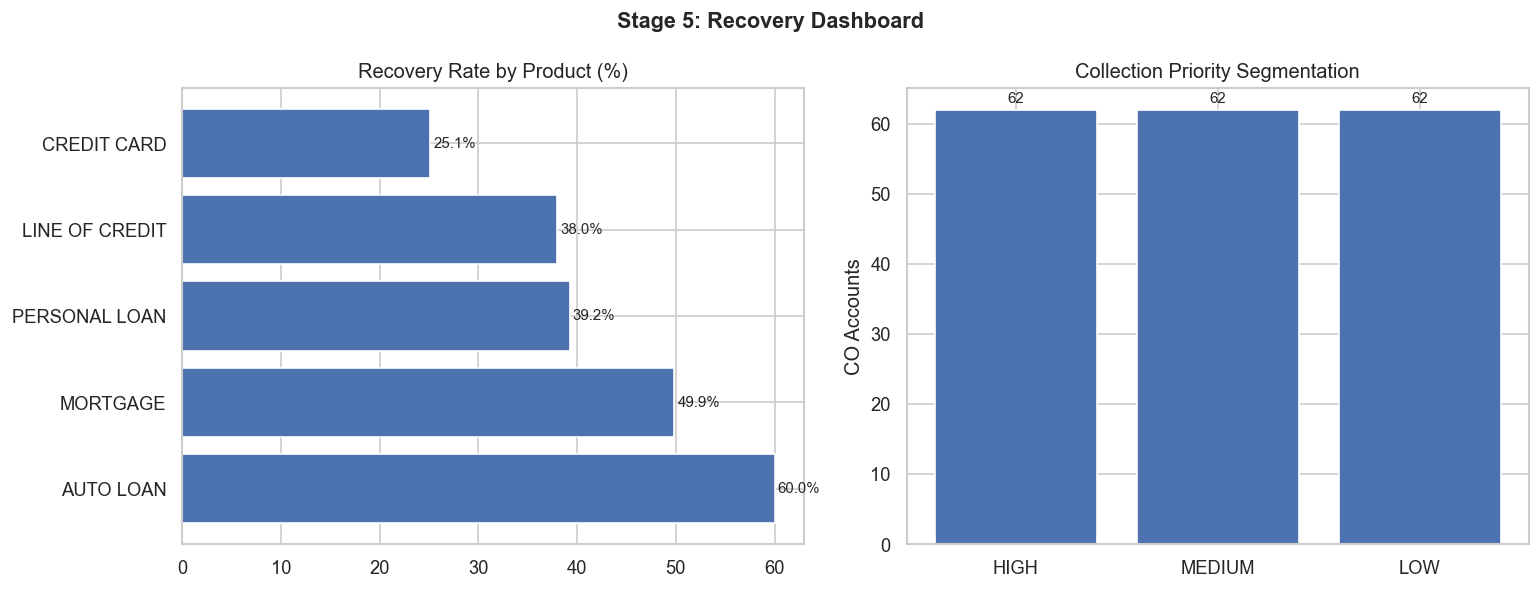


✅ Stage 5 complete


In [45]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STEP 1: Create two charts
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fig.suptitle(
    'Stage 5: Recovery Dashboard',
    fontsize=13,
    fontweight='bold'
)


# ---------------------------------------------------------
# STEP 2: Calculate Recovery Rate by Product
# ---------------------------------------------------------

recovery_rate = {}

for product in co['BORROWING_TYPE'].unique():

    product_data = co[co['BORROWING_TYPE'] == product]

    total_recovered = product_data['recovered'].sum()

    total_balance = product_data['outstanding_balance'].sum()

    rate = (total_recovered / total_balance) * 100

    recovery_rate[product] = rate


# Convert dictionary to Series
rr = pd.Series(recovery_rate)

# Sort from highest to lowest
rr = rr.sort_values(ascending=False)


# ---------------------------------------------------------
# STEP 3: Create Recovery Rate Bar Chart
# ---------------------------------------------------------

axes[0].barh(
    rr.index,
    rr.values
)

axes[0].set_title('Recovery Rate by Product (%)')


# Write percentage on each bar
for i in range(len(rr)):

    value = rr.values[i]

    axes[0].text(
        value + 0.3,
        i,
        f'{value:.1f}%',
        va='center',
        fontsize=9
    )


# ---------------------------------------------------------
# STEP 4: Count Collection Priority
# ---------------------------------------------------------

priority_counts = co['priority'].value_counts()

# Arrange in HIGH, MEDIUM, LOW order
priority_counts = priority_counts.reindex(
    ['HIGH', 'MEDIUM', 'LOW']
)


# ---------------------------------------------------------
# STEP 5: Create Priority Chart
# ---------------------------------------------------------

axes[1].bar(
    priority_counts.index,
    priority_counts.values
)

axes[1].set_title('Collection Priority Segmentation')

axes[1].set_ylabel('CO Accounts')


# Write account count on each bar
for i in range(len(priority_counts)):

    value = priority_counts.values[i]

    axes[1].text(
        i,
        value + 1,
        str(value),
        ha='center',
        fontsize=9
    )


# ---------------------------------------------------------
# STEP 6: Adjust the Dashboard
# ---------------------------------------------------------

plt.tight_layout()


# ---------------------------------------------------------
# STEP 7: Save the Dashboard
# ---------------------------------------------------------

plt.savefig(
    'stage5_recovery.png',
    bbox_inches='tight'
)


# ---------------------------------------------------------
# STEP 8: Display the Dashboard
# ---------------------------------------------------------

plt.show()


print('\n✅ Stage 5 complete')

In [48]:
print(recovery_rate)
print(type(recovery_rate))

{'CREDIT CARD': np.float64(25.14093088587827), 'PERSONAL LOAN': np.float64(39.234937529040586), 'MORTGAGE': np.float64(49.85206307906777), 'LINE OF CREDIT': np.float64(37.95319570881435), 'AUTO LOAN': np.float64(60.00071889733366)}
<class 'dict'>


In [56]:
# =========================================================
# CREDIT RISK FINAL SUMMARY
# =========================================================

# Calculate overall recovery rate again
total_recovered = co['recovered'].sum()

total_co_balance = co['outstanding_balance'].sum()

overall_recovery_rate = (
    total_recovered / total_co_balance
) * 100


# =========================================================
# PRINT FINAL SUMMARY
# =========================================================

print("=" * 50)
print("       CREDIT RISK FINAL SUMMARY")
print("=" * 50)

print("Original Applications :", 10108)

print("After Cleaning        :", total_apps)

print("Approval Rate         :",
      round(total_approved / total_apps * 100, 1), "%")

print("Booking Rate          :",
      round(total_booked / total_apps * 100, 1), "%")

print("Portfolio BCR         :",
      round(bcr, 2), "x")

print("LightGBM  AUC         :",
      round(auc_lgb, 3))

print("Logistic Regression AUC:",
      round(auc_lr, 3))

print("Expected Loss         :",
      round(total_expected_loss / 1e7, 2), "Crore")

print("Expected Loss (%)     :",
      round(
          total_expected_loss / perf_df["ead"].sum() * 100,
          2
      ), "%")

print("Charge-Off Pay Rate   :",
      round(pay_rate, 1), "%")

print("Recovery Rate         :",
      round(overall_recovery_rate, 1), "%")

print("=" * 50)

print("Credit Risk Pipeline Completed")


       CREDIT RISK FINAL SUMMARY
Original Applications : 10108
After Cleaning        : 9194
Approval Rate         : 66.5 %
Booking Rate          : 60.5 %
Portfolio BCR         : 7.58 x
LightGBM  AUC         : 0.531
Logistic Regression AUC: 0.53
Expected Loss         : 80.76 Crore
Expected Loss (%)     : 9.04 %
Charge-Off Pay Rate   : 53.8 %
Recovery Rate         : 42.9 %
Credit Risk Pipeline Completed


---
## 🎯 Interview Cheat Sheet — Approach 1 (Real Data + Cleaning Edition)

### The 60-second pitch:
*"I built a 5-stage credit risk pipeline on real loan data — 10,108 applications, 5 products, 2016–2020. Stage 1 audits and cleans the raw data using drop + impute strategy with a full audit trail. Stage 2 applies credit policy rules. Stage 3 tracks delinquency and BCR. Stage 4 trains Logistic Regression and Random Forest with product-specific LGDs in the IFRS9 Expected Loss formula. Stage 5 segments Charge-Off accounts by collection priority."*

### Top data cleaning questions:

| Question | Key Answer |
|----------|-----------|
| How did you handle null REQUESTED_AMOUNT? | Dropped — you cannot underwrite a loan with no amount. These are abandoned applications. |
| Why mode for BORROWING_TYPE, not drop? | Product is non-critical for cleaning but needed for modelling. Mode imputation preserves the majority signal without data loss. |
| Why median per product for TENURE? | MORTGAGE tenure (15–30 yr) ≠ CREDIT CARD tenure (3 yr). Global median would be wrong. Product-level median is contextually correct. |
| How did you fix Region nulls? | First derived from State using a lookup map. Only residual unknowns got 'Unknown'. Never impute geography with mode — it introduces geographic bias. |
| What % of data did you drop? | ~9% — only rows with missing REQUESTED_AMOUNT or APPLICATION_DATE. Acceptable loss to preserve data integrity. |

### Top ML questions:

| Question | Key Answer |
|----------|-----------|
| Why class_weight='balanced'? | Real default rate is 5–10%. Without balancing, model predicts everyone as non-default and still gets 92% accuracy — useless for credit risk. |
| Why product-specific LGD? | IFRS9 requires it. Mortgage has collateral (property), LGD~20%. Credit Card is unsecured revolving, LGD~75%. Same EAD but very different provision. |
| What's next? | Streamlit dashboard (Approach 5), LLM explanation layer with Claude API (Approach 3). |
